# Organization

dataset link: https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification


Participants:
- Pedico Simone
- Piatti Davide
- Desantis Amedeo


# Goal and ideas

Starting from the dataset available at the link above, we will train two predictive models, a neural network (NN) and a decision tree, and then compare their performance.
The dataset we chose contains the results of 2126 cardiotocograms, a clinical exam that monitors the heartbeat of a fetus and the contractions of the mother's uterus.
Cardiotocograms (CTGs) are a simple and affordable exam for assessing fetal health, making it possible to act to prevent both child and maternal mortality. The exam consists of sending ultrasound pulses and reading the response, thereby obtaining information on the fetal heart rate (FHR), fetal movements, uterine contractions and more.
The goal is therefore to classify the health status of a fetus (fetal_health) based on the results of the clinical exam.

the values of fetal_health are the following:
- normal (1)
- suspect (2)
- pathological (3)

# Library imports

In [ ]:
import kagglehub

# data structures
import numpy as np
import pandas as pd

# plots and data visualization
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ML algorithms, ML model evaluation and data processing
import sklearn as sn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.metrics import f1_score, classification_report, accuracy_score, confusion_matrix, roc_curve, auc, fbeta_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

# hypothesis testing
from scipy import stats
import scipy.stats as st

# neural networks
import keras
from keras.models import Sequential
from keras.layers import Dense
import keras.backend as K

# decision trees
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Dataset import

In [ ]:
path = kagglehub.dataset_download("andrewmvd/fetal-health-classification")
print("percorso al dataset:", path)

df_originale = pd.read_csv ("/root/.cache/kagglehub/datasets/andrewmvd/fetal-health-classification/versions/1/fetal_health.csv")

100%|██████████| 45.8k/45.8k [00:00<00:00, 5.23MB/s]

Extracting files...
percorso al dataset: /root/.cache/kagglehub/datasets/andrewmvd/fetal-health-classification/versions/1


#Exploratory data analysis

## Preliminary changes to the dataset


In [ ]:
df_originale.dtypes

,0
baseline value,float64
accelerations,float64
fetal_movement,float64
uterine_contractions,float64
light_decelerations,float64
severe_decelerations,float64
prolongued_decelerations,float64
abnormal_short_term_variability,float64
mean_value_of_short_term_variability,float64
percentage_of_time_with_abnormal_long_term_variability,float64


In [ ]:
df_originale['fetal_health'].unique()

array([2., 1., 3.])

In [ ]:
# the last column is the target variable
variabili_numeriche = list(df_originale.columns[:-1])
print(variabili_numeriche)

['baseline value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_min', 'histogram_max', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean', 'histogram_median', 'histogram_variance', 'histogram_tendency']


### Main dataset issues (related to the target column)
We need to modify the dataset and fix these two issues:

*   The target variable is float instead of integer
*   The classes start from 1 instead of 0



### Fixing the issues related to the target column

In [ ]:
# change the type of the target variable from float to int.
# DecisionTree in fact requires "an array Y of integer values, shape
# (n_samples,), holding the class labels for the training samples."
df_originale['fetal_health'] = df_originale['fetal_health'].astype(int)

# change the class labels from [1, 2, 3] to [0, 1 , 2].
# DecisionTree in fact requires the classes to be labelled starting from
# 0 for multiclass classification problems
df_originale['fetal_health'] = df_originale['fetal_health'] -1

In [ ]:
etichette_classi = np.sort(df_originale['fetal_health'].unique())
print(etichette_classi)

[0 1 2]


In [ ]:
df_originale.dtypes

,0
baseline value,float64
accelerations,float64
fetal_movement,float64
uterine_contractions,float64
light_decelerations,float64
severe_decelerations,float64
prolongued_decelerations,float64
abnormal_short_term_variability,float64
mean_value_of_short_term_variability,float64
percentage_of_time_with_abnormal_long_term_variability,float64


## Descriptive statistics of the dataset

In [ ]:
df_originale.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,1
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,0


In [ ]:
df_originale.describe()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
count,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.00000,...,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,133.303857,0.003178,0.009481,0.004366,0.001889,0.000003,0.000159,46.990122,1.332785,9.84666,...,93.579492,164.025400,4.068203,0.323612,137.452023,134.610536,138.090310,18.808090,0.320320,0.304327
std,9.840844,0.003866,0.046666,0.002946,0.002960,0.000057,0.000590,17.192814,0.883241,18.39688,...,29.560212,17.944183,2.949386,0.706059,16.381289,15.593596,14.466589,28.977636,0.610829,0.614377
min,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.200000,0.00000,...,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,0.000000
25%,126.000000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000,32.000000,0.700000,0.00000,...,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,0.000000
50%,133.000000,0.002000,0.000000,0.004000,0.000000,0.000000,0.000000,49.000000,1.200000,0.00000,...,93.000000,162.000000,3.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,0.000000
75%,140.000000,0.006000,0.003000,0.007000,0.003000,0.000000,0.000000,61.000000,1.700000,11.00000,...,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,0.000000
max,160.000000,0.019000,0.481000,0.015000,0.015000,0.001000,0.005000,87.000000,7.000000,91.00000,...,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,2.000000


## Features with low standard deviation
These are irrelevant features.

In [ ]:
# compute the standard deviation of each variable
std_dev = df_originale[:-1].std()

# set a lower bound for the standard deviation of the variables
threshold = 0.1

# filter the variables whose standard deviation is below the threshold
low_std_dev_features = std_dev[std_dev < threshold].index.tolist()

print(f"Variabili con deviazione standard inferiore a {threshold}:")
low_std_dev_features

Variabili con deviazione standard inferiore a 0.1:


['accelerations',
 'fetal_movement',
 'uterine_contractions',
 'light_decelerations',
 'severe_decelerations',
 'prolongued_decelerations']

## Analysis of the target feature distribution

In [ ]:
df_originale["fetal_health"].value_counts()

,count
fetal_health,
0,1655
1,295
2,176


The dataset is heavily imbalanced.

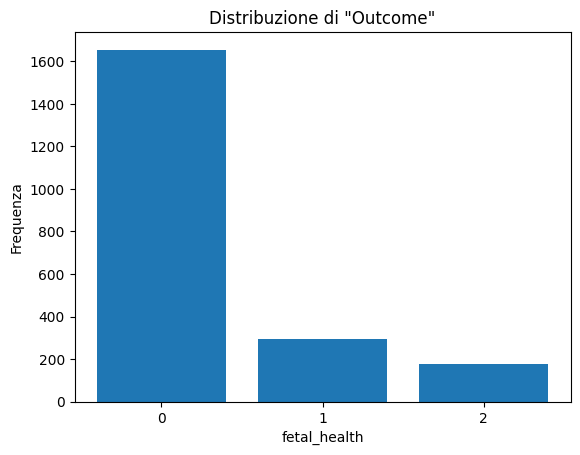

In [ ]:
plt.bar(np.sort(df_originale["fetal_health"].unique()), df_originale["fetal_health"].value_counts())
plt.xlabel("fetal_health")
plt.ylabel("Frequenza")
plt.title("Distribuzione di \"Outcome\"")
plt.xticks([2,1,0])
plt.show()

The problem is imbalanced => from https://scikit-learn.org/1.5/modules/tree.html#classification "Balance your dataset before training to prevent the tree from being biased toward the classes that are dominant. Class balancing can be done by sampling an equal number of samples from each class...".

## Downsampling for imbalanced problems

In [ ]:
# normalize the dataset
scaler = StandardScaler()
scaler = scaler.fit(df_originale[variabili_numeriche])

df_originale_scaled = scaler.transform(df_originale[variabili_numeriche])
df_originale_scaled = pd.DataFrame(df_originale_scaled, columns=df_originale[variabili_numeriche].columns)

# normalized dataset
df_originale_scaled["fetal_health"] = df_originale["fetal_health"]

In [ ]:
target_name = "fetal_health"

df_majority = df_originale_scaled[df_originale_scaled[target_name] == 0]
df_minority_1 = df_originale_scaled[df_originale_scaled[target_name] == 1]
df_minority_2 = df_originale_scaled[df_originale_scaled[target_name] == 2]

# number of samples of the dominant class to keep
min_sample_number = int(np.mean([len(df_minority_1), len(df_minority_2)]))

# randomly draw minsample samples of class 0
downsampled_majority = df_majority.sample(n=min_sample_number, random_state=42)

# remove these samples
df_scaled_data_removed = df_majority.drop(downsampled_majority.index)

# combine the dataframes of the three classes to obtain the final downsampled dataset
df_scaled_downsampled = pd.concat([downsampled_majority, df_minority_1, df_minority_2])

print(df_scaled_downsampled[target_name].value_counts())

fetal_health
1    295
0    235
2    176
Name: count, dtype: int64


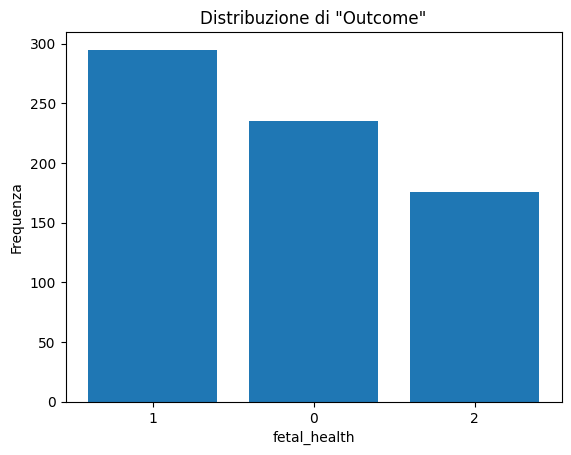

In [ ]:
plt.bar(df_scaled_downsampled["fetal_health"].unique(), df_scaled_downsampled["fetal_health"].value_counts())
plt.xlabel("fetal_health")
plt.ylabel("Frequenza")
plt.title("Distribuzione di \"Outcome\"")
plt.xticks(df_scaled_downsampled["fetal_health"].unique(), ['1','0','2'])
plt.show()

## PCA

We compute the principal components of the downsampled dataset

In [ ]:
# compute the principal components of the downsampled dataset
pca = PCA().fit(df_scaled_downsampled[variabili_numeriche])

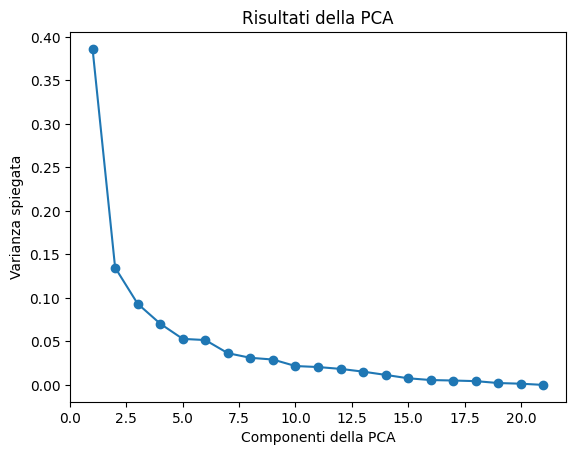

In [ ]:
# plot of the variance explained by each principal component
plt.plot(range(1, pca.n_components_ + 1), pca.explained_variance_ratio_, marker='o')
plt.xlabel('Componenti della PCA')
plt.ylabel('Varianza spiegata')
plt.title("Risultati della PCA")
plt.show()

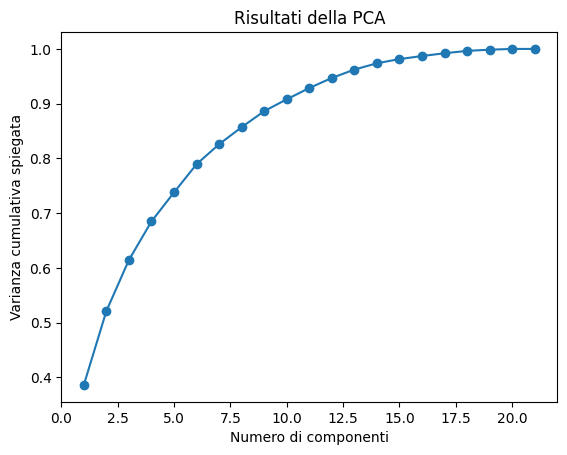

In [ ]:
# compute the cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# plot of the cumulative variance
plt.plot(range(1, pca.n_components_ + 1), cumulative_variance, marker='o')
plt.xlabel('Numero di componenti')
plt.ylabel('Varianza cumulativa spiegata')
plt.title('Risultati della PCA')
plt.show()

In [ ]:
pca.n_components_

21

In [ ]:
# quantify the percentage of variance explained by each of the components.
pca.explained_variance_ratio_

array([3.86299513e-01, 1.34889569e-01, 9.33102395e-02, 7.04167331e-02,
       5.29190276e-02, 5.15986572e-02, 3.64922281e-02, 3.11767940e-02,
       2.91894075e-02, 2.17064914e-02, 2.05711509e-02, 1.84267529e-02,
       1.52678366e-02, 1.15220021e-02, 7.63329922e-03, 5.61356601e-03,
       5.05324381e-03, 4.34545593e-03, 2.16365501e-03, 1.40437750e-03,
       3.91346944e-18])

In [ ]:
df_feature_importance = pd.DataFrame(pca.explained_variance_ratio_, index=variabili_numeriche, columns=["varianza spiegata"])
df_feature_importance.sort_values(by="varianza spiegata", ascending=False)

,varianza spiegata
baseline value,3.862995e-01
accelerations,1.348896e-01
fetal_movement,9.331024e-02
uterine_contractions,7.041673e-02
light_decelerations,5.291903e-02
severe_decelerations,5.159866e-02
prolongued_decelerations,3.649223e-02
abnormal_short_term_variability,3.117679e-02
mean_value_of_short_term_variability,2.918941e-02
percentage_of_time_with_abnormal_long_term_variability,2.170649e-02


In [ ]:
cumulative_variance

array([0.38629951, 0.52118908, 0.61449932, 0.68491605, 0.73783508,
       0.78943374, 0.82592597, 0.85710276, 0.88629217, 0.90799866,
       0.92856981, 0.94699656, 0.9622644 , 0.9737864 , 0.9814197 ,
       0.98703327, 0.99208651, 0.99643197, 0.99859562, 1.        ,
       1.        ])

We determine the minimum number of principal components that explain 95% of the variance of the downsampled dataset

In [ ]:
n_components = np.where(cumulative_variance >= 0.95)[0][0] + 1

print(f"Numero di componenti per spiegare il 95% della varianza: {n_components}")

Numero di componenti per spiegare il 95% della varianza: 13


### Dataset transformation

In [ ]:
# apply PCA to reduce the dimensionality of the data
pca = PCA(n_components=n_components).fit(df_scaled_downsampled[variabili_numeriche])
pca_data = pca.transform(df_scaled_downsampled[variabili_numeriche])
pca_data_removed = pca.transform(df_scaled_data_removed[variabili_numeriche])
pca_data_originale = pca.transform(df_originale_scaled[variabili_numeriche])

### Plot of the dataset distribution along the first two principal components

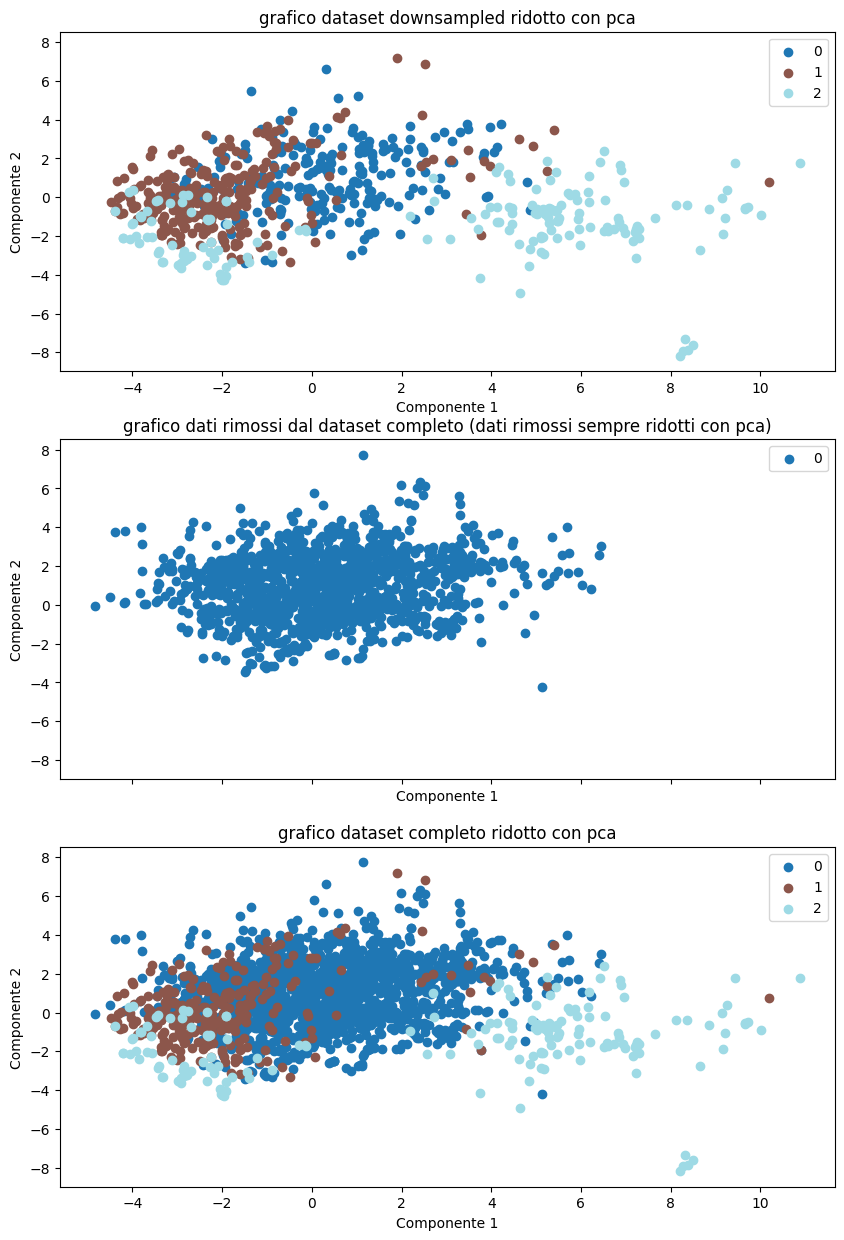

In [ ]:
# create a label-->color code map
unique_labels = np.unique(df_scaled_downsampled["fetal_health"])
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))
label_to_color = dict(zip(unique_labels, colors))

# plot of the downsampled dataset reduced with pca
fig, (ax, ax1, ax2) =  plt.subplots(3, 1, figsize=(10, 15), sharex=True, sharey=True)
for label in unique_labels:
    mask = (df_scaled_downsampled["fetal_health"] == label).values
    ax.scatter(pca_data[mask, 0], pca_data[mask, 1], color=label_to_color[label], label=label)
ax.set_title("grafico dataset downsampled ridotto con pca")
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.tick_params(labelbottom=True)
ax.legend()

# plot of the data removed from the full dataset during the downsampling phase
# (removed data also transformed with pca)
for label in np.unique(df_scaled_data_removed["fetal_health"]):
    mask = (df_scaled_data_removed["fetal_health"] == label).values
    ax1.scatter(pca_data_removed[mask, 0], pca_data_removed[mask, 1], color=label_to_color[label], label=label)

ax1.set_title("grafico dati rimossi dal dataset completo (dati rimossi sempre ridotti con pca)")
ax1.set_xlabel('Componente 1')
ax1.set_ylabel('Componente 2')
ax1.legend()

# plot of the full dataset reduced with pca
for label in np.unique(df_originale["fetal_health"]):
    mask = (df_originale["fetal_health"] == label).values
    ax2.scatter(pca_data_originale[mask, 0], pca_data_originale[mask, 1], color=label_to_color[label], label=label)

ax2.set_title("grafico dataset completo ridotto con pca")
ax2.set_xlabel('Componente 1')
ax2.set_ylabel('Componente 2')
ax2.legend()

plt.show()

### Analysis of the most important features

loadings = pca.components_


The loadings represent the contribution of each original variable to the principal components.

In [ ]:
print(pca.components_)

[[-1.79419315e-01  2.61705497e-02  8.39778582e-02  1.36341449e-01
   2.25832538e-01  1.04654545e-01  3.42037391e-01 -8.97728905e-02
   2.68354768e-01 -2.42011183e-01 -5.72249992e-02  2.59190904e-01
  -2.70013025e-01  1.17883269e-01  1.93901855e-01  9.60728576e-02
  -3.13549955e-01 -3.33161310e-01 -3.00622082e-01  3.21981438e-01
  -1.28278706e-01]
 [ 1.83170554e-01  1.50198529e-01  2.81939696e-02  1.33851345e-01
   2.65234250e-02 -2.83842858e-01 -1.19567884e-01 -2.33996258e-01
   1.72895907e-01 -2.79752818e-01  2.25455102e-01  2.90867872e-01
  -1.74708397e-01  3.43651319e-01  2.52218643e-01  1.71633092e-01
   3.10717398e-01  2.50540887e-01  2.98016194e-01  5.54896433e-02
   1.95877308e-01]
 [-5.03040431e-02  5.57172198e-02 -2.00093367e-01  6.34009218e-02
   1.02157358e-01  8.13152134e-01 -4.43061479e-01 -9.85852167e-02
   3.39167677e-02 -1.33123568e-01  1.39987712e-01  5.33653755e-02
  -6.96435097e-02  1.12617291e-03 -2.86602165e-03  1.33015066e-01
  -1.03567922e-03  3.51037668e-02  2.8

#### Heatmap of the loadings

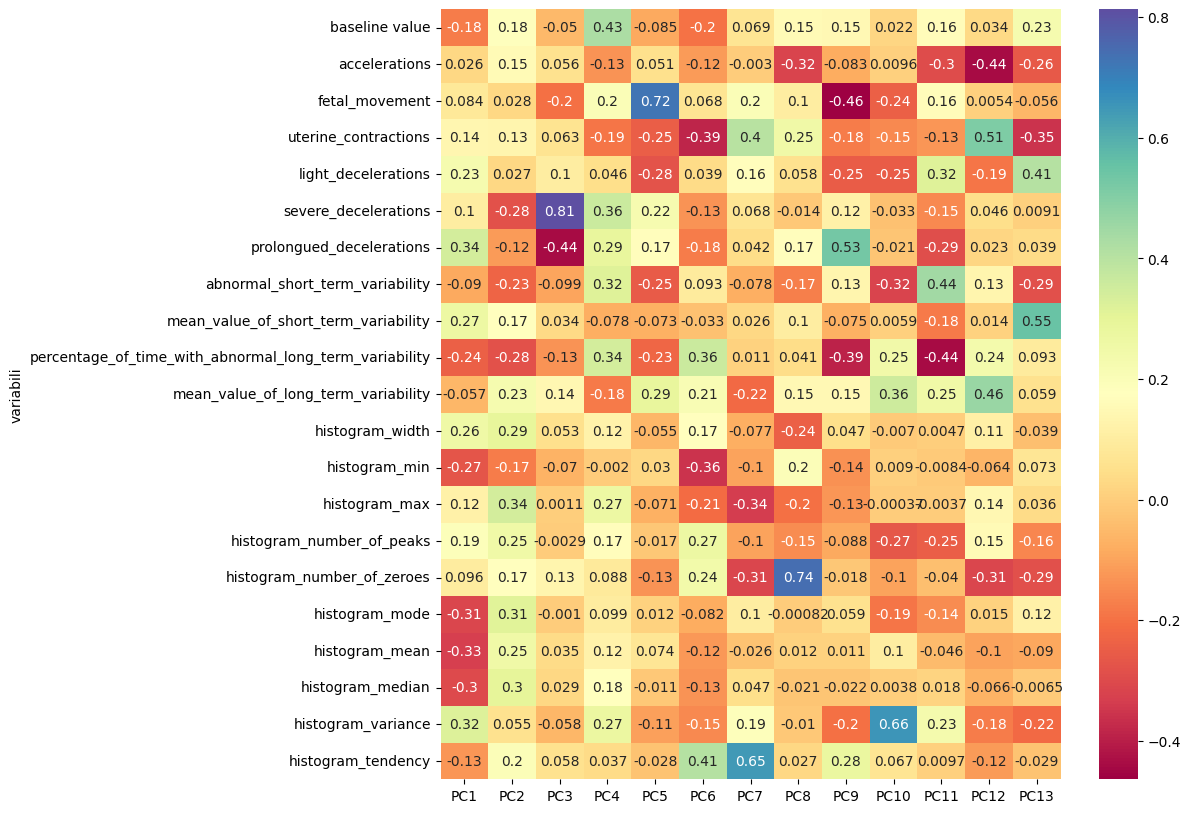

In [ ]:
numero_pc = pca.n_features_in_
pc_list = ["PC"+str(i) for i in list(range(1, numero_pc+1))]

loadings = pca.components_
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variabili'] = variabili_numeriche
loadings_df = loadings_df.set_index('variabili')

# heatmap plot
plt.figure(figsize=(10, 10))
ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

#### Biplot of the loadings (for the first two principal components)


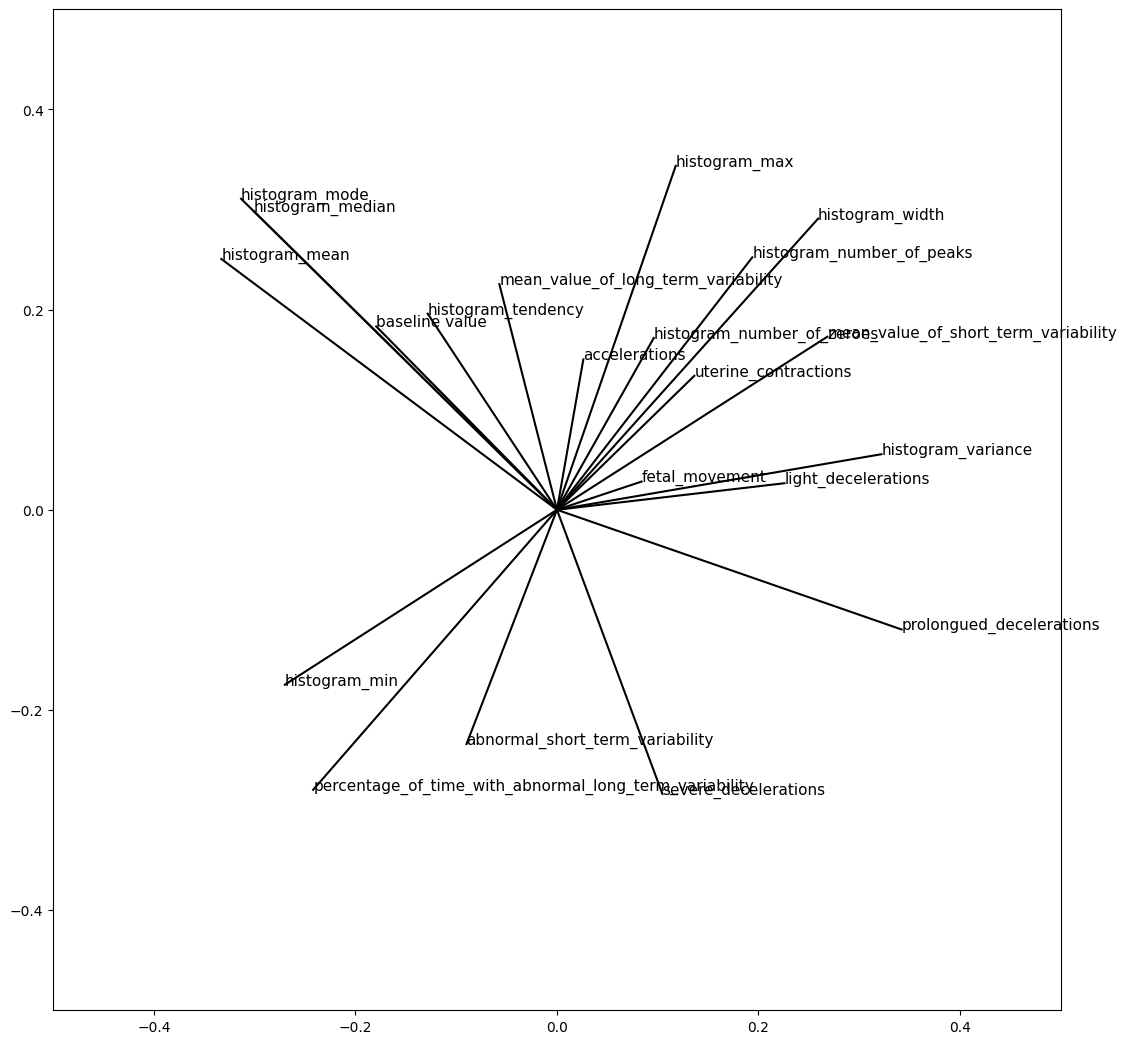

In [ ]:
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlim([-0.5, 0.5])
ax.set_ylim([-0.5, 0.5])

for i, (x, y) in enumerate(zip(loadings[0, :], loadings[1, :])):
    # draw the line from the origin to the point (x, y)
    ax.plot([0, x], [0, y], color='k')
    # draw the label of the line
    ax.text(x, y, df_originale.columns[i], fontsize='11')

#### Covariance matrix of the downsampled dataset

PCA makes it possible to aggregate into a single component the variables that are strongly correlated with each other, as in the case of the variables "histogram_mean", "histogram_mode" and "histogram_median".

If two or more variables are highly correlated, it means they contain similar information. PCA combines them into a new principal component that captures their shared variance.
This reduces redundancy and makes it possible to represent more information with fewer dimensions.

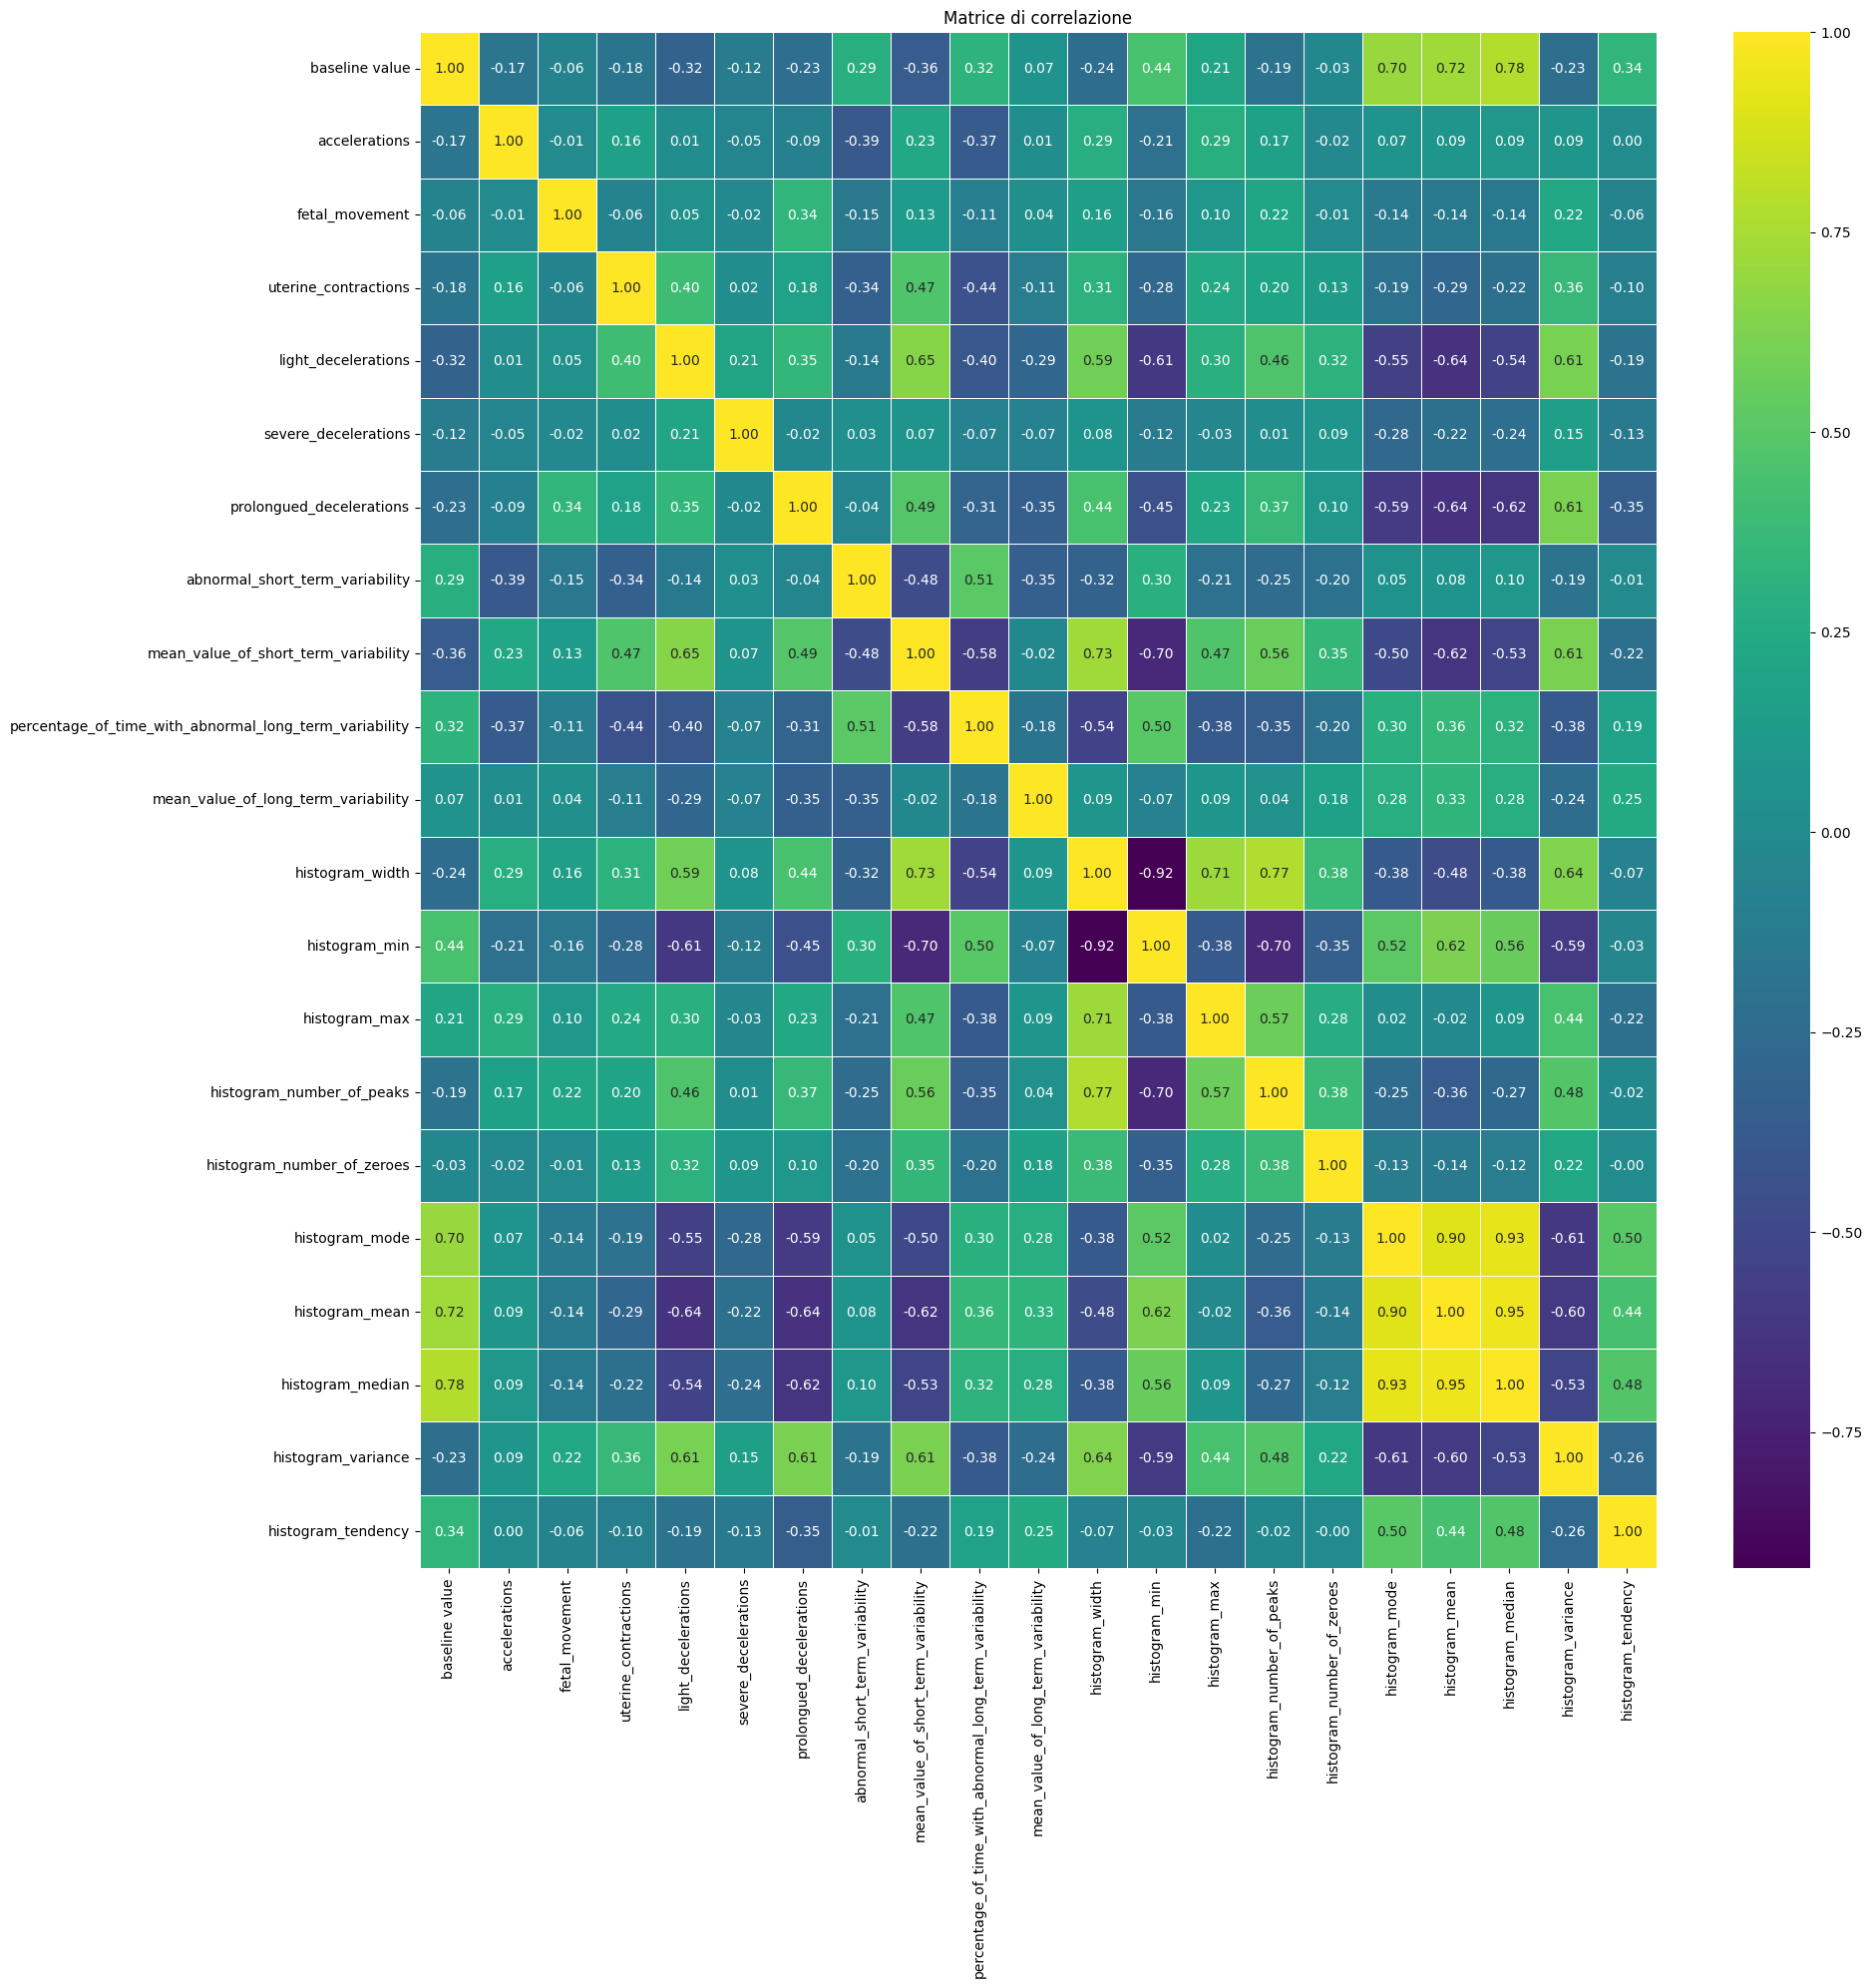

In [ ]:
correlation_matrix = df_scaled_downsampled[variabili_numeriche].corr()

# plot of the covariance matrix
plt.figure(figsize=(20, 20))
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Matrice di correlazione')
plt.show()

#### Study of the distribution of a variable of interest

In [ ]:
feature_to_study = "histogram_mean"

In [ ]:
feature_range = df_originale[feature_to_study].max() - df_originale[feature_to_study].min()
max_v = df_originale[feature_to_study].max()
min_v = df_originale[feature_to_study].min()
mean_v = df_originale[feature_to_study].mean()
std_dev_v = df_originale[feature_to_study].std()

print(f"il range di valori che assume la variabile {feature_to_study} è: {feature_range}")
print(f"valore massimo: {max_v}")
print(f"valore minimo: {min_v}")
print(f"valore medio: {mean_v}")
print(f"deviazione standard: {std_dev_v}")

il range di valori che assume la variabile histogram_mean è: 109.0
valore massimo: 182.0
valore minimo: 73.0
valore medio: 134.61053621825025
deviazione standard: 15.593596332563022


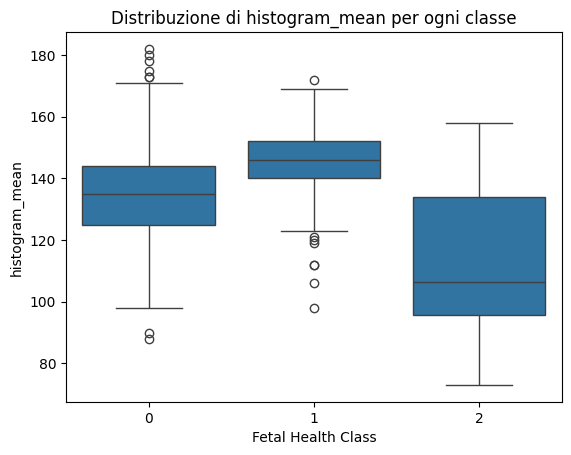

In [ ]:
# box plot of the variable of interest
sns.boxplot(x="fetal_health", y=feature_to_study, data=df_originale)

plt.title(f"Distribuzione di {feature_to_study} per ogni classe")
plt.xlabel("Fetal Health Class")
plt.ylabel(feature_to_study)
plt.show()

# NN

## Helper functions for the NNs

### Function that creates an NN

In [ ]:
def crea_rete_neurale(input_shape, num_classi, metrica=['accuracy']):

  model = Sequential()
  model.add(Dense(input_shape, input_shape=(input_shape,), activation='sigmoid'))
  model.add(Dense(input_shape, activation='sigmoid'))
  model.add(Dense(input_shape, activation='sigmoid'))
  model.add(Dense(num_classi, activation='sigmoid'))

  # Compile the model
  model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=metrica)

  return model

### Function that prints the classification report to the console

In [ ]:
# function that prints to the console the report for the test of an nn
def classificatin_report_nn(model, X_test, y_test):

  prediction = model.predict(X_test)

  # get the original labels (not one-hot)
  y_true = np.argmax(y_test, axis=1)
  y_pred_test_std = np.argmax(prediction, axis=1)

  # generate the classification report
  print(classification_report(y_true, y_pred_test_std, target_names=["Normal", "Suspect", "Pathological"]))

  cm = confusion_matrix(y_true, y_pred_test_std)
  print("matrice di confusione\n")
  print(cm)

  # compute the F2-score for each class
  # the F2-score puts more emphasis on recall than the F1-score
  #print("\nF2-score per ogni classe\n")
  #for class_idx in np.sort(df_originale["fetal_health"].unique()):
  #  print(f"F2-score per la classe {class_idx}: {fbeta_score(y_true, y_pred_test_std, beta = 2, average = 'macro', labels=[class_idx])}")

### Function that plots the training metrics

In [ ]:
def plot_metriche_training(history):

  print(history.history.keys())

  for key in history.history.keys():
    plt.plot(history.history[key])

  plt.ylabel('')
  plt.xlabel('epoch')
  plt.legend(history.history.keys(), loc='lower right')
  plt.show()

## NN_downsampled

This is the network trained on the dataset reduced with downsampling and transformed with PCA.

### Splitting of the downsampled dataset

In [ ]:
X_train_downsampled, X_test_downsampled, y_train_downsampled, y_test_downsampled = train_test_split(pca_data, df_scaled_downsampled["fetal_health"], test_size=0.3, random_state=42)

# the full test also includes the class 0 examples removed during the
# downsampling phase of the dataset.
# the goal is to test the behaviour of the network trained on
# a balanced training set, on an imbalanced test set.
X_test_completo = np.concatenate((X_test_downsampled, pca_data_removed))
y_test_completo = np.concatenate((y_test_downsampled, df_scaled_data_removed["fetal_health"]))

# one-hot encode the target variable
y_test_completo = keras.utils.to_categorical(y_test_completo, num_classes=3)
y_train_downsampled = keras.utils.to_categorical(y_train_downsampled, num_classes=3)
y_test_downsampled = keras.utils.to_categorical(y_test_downsampled, num_classes=3)

### Functions for training the downsampled network

In [ ]:
# function that computes the recall for the suspect samples
def recall_suspect(y_true, y_pred):
  # convert the probabilities into class predictions (0, 1, 2)
  y_pred_labels = tf.argmax(y_pred, axis=1)
  y_true_labels = tf.argmax(y_true, axis=1)

  # find the indices of the disease cases (not healthy) in y_true
  malati_indices = tf.where(y_true_labels == 1)

  # retrieve the true and predicted labels for the disease cases
  y_true_malati = tf.gather_nd(y_true_labels, malati_indices)
  y_pred_malati = tf.gather_nd(y_pred_labels, malati_indices)

  # compute TP and FN using vectorized tensor operations
  TP = tf.reduce_sum(tf.cast(tf.equal(y_true_malati, y_pred_malati), tf.float32))
  FN = tf.cast(tf.shape(y_true_malati)[0], tf.float32) - TP

  # compute the recall
  recall = tf.cond(tf.not_equal(TP + FN, 0.0),
                   lambda: TP / (TP + FN),
                   lambda: 0.0)
  return recall

# function that computes the recall for the pathological samples
def recall_pathologic(y_true, y_pred):
  # convert the probabilities into class predictions (0, 1, 2)
  y_pred_labels = tf.argmax(y_pred, axis=1)
  y_true_labels = tf.argmax(y_true, axis=1)

  # find the indices of the disease cases (not healthy) in y_true
  malati_indices = tf.where(y_true_labels == 2)

  # retrieve the true and predicted labels for the disease cases
  y_true_malati = tf.gather_nd(y_true_labels, malati_indices)
  y_pred_malati = tf.gather_nd(y_pred_labels, malati_indices)

  # compute TP and FN using vectorized tensor operations
  TP = tf.reduce_sum(tf.cast(tf.equal(y_true_malati, y_pred_malati), tf.float32))
  FN = tf.cast(tf.shape(y_true_malati)[0], tf.float32) - TP

  # compute the recall
  recall = tf.cond(tf.not_equal(TP + FN, 0.0),
                  lambda: TP / (TP + FN),
                  lambda: 0.0)
  return recall

### Network creation

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


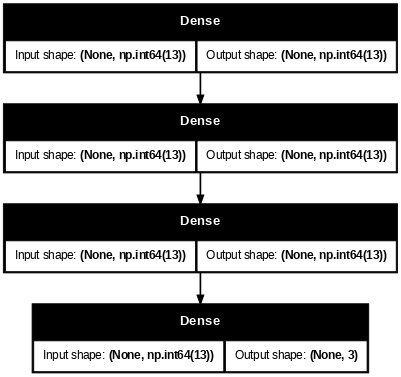

In [ ]:
nn_on_pca_downsampled = crea_rete_neurale(input_shape=n_components, num_classi=3, metrica=[recall_suspect, recall_pathologic])
keras.utils.plot_model(nn_on_pca_downsampled, show_shapes=True, dpi=60)

### Network training

In [ ]:
history_model_pca_downsampled = nn_on_pca_downsampled.fit(X_train_downsampled, y_train_downsampled, epochs=200, batch_size=20, verbose=1)

Epoch 1/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.1869 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 2/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0834 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 3/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0637 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 4/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0421 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 5/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0311 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 6/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0213 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 7/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0064 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 8/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9993 - recall_pathologic: 0.0000e+00 - recall_suspect: 1.0000
Epoch 9/200
25/2

In [ ]:
history_model_pca_downsampled.history

{'loss': [1.1869741678237915,
  1.097934603691101,
  1.0559592247009277,
  1.039907455444336,
  1.0293103456497192,
  1.018559217453003,
  1.0063380002975464,
  0.9920483827590942,
  0.9755180478096008,
  0.9575541615486145,
  0.936200737953186,
  0.9137508869171143,
  0.8868544101715088,
  0.8598482012748718,
  0.8299526572227478,
  0.7999577522277832,
  0.7693575024604797,
  0.7386846542358398,
  0.7097736597061157,
  0.6792023181915283,
  0.6538640856742859,
  0.6273818016052246,
  0.6047855615615845,
  0.5853115916252136,
  0.5664297342300415,
  0.5496019124984741,
  0.5351178050041199,
  0.5225621461868286,
  0.5119099617004395,
  0.5021273493766785,
  0.492003858089447,
  0.4846934974193573,
  0.4767564833164215,
  0.47108355164527893,
  0.46426650881767273,
  0.45989200472831726,
  0.45395517349243164,
  0.44916194677352905,
  0.44549086689949036,
  0.4413723945617676,
  0.4376821219921112,
  0.4343731105327606,
  0.43146100640296936,
  0.428095281124115,
  0.42521172761917114,


dict_keys(['loss', 'recall_pathologic', 'recall_suspect'])


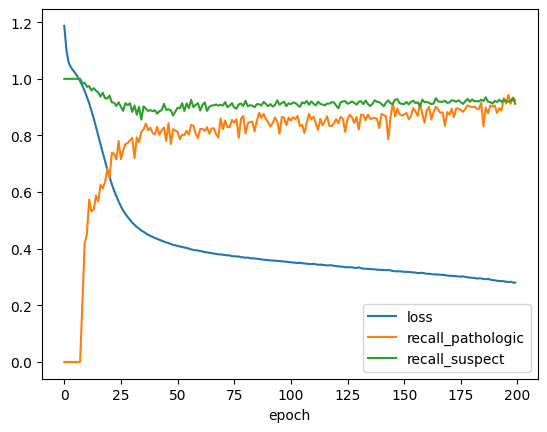

In [ ]:
plot_metriche_training(history_model_pca_downsampled)

### Testing the network on the downsampled test set

In [ ]:
classificatin_report_nn(nn_on_pca_downsampled, X_test_downsampled, y_test_downsampled)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
              precision    recall  f1-score   support

      Normal       0.88      0.86      0.87        81
     Suspect       0.83      0.87      0.85        82
Pathological       0.89      0.84      0.86        49

    accuracy                           0.86       212
   macro avg       0.86      0.86      0.86       212
weighted avg       0.86      0.86      0.86       212

matrice di confusione

[[70  9  2]
 [ 8 71  3]
 [ 2  6 41]]


### Testing the network on the full test set (downsampled test set + data removed during the dataset downsampling phase)

In [ ]:
classificatin_report_nn(nn_on_pca_downsampled, X_test_completo, y_test_completo)

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

      Normal       0.99      0.85      0.92      1501
     Suspect       0.25      0.87      0.39        82
Pathological       0.65      0.84      0.73        49

    accuracy                           0.85      1632
   macro avg       0.63      0.85      0.68      1632
weighted avg       0.94      0.85      0.88      1632

matrice di confusione

[[1277  205   19]
 [   8   71    3]
 [   2    6   41]]


Interpretation of the results:

If the network classifies an instance as normal, then with 99% certainty the instance really is normal.
However, the network is able to find only 86% of the true normals.

If the network classifies an instance as  suspect, in 27% of cases the instance is truly suspect. The network is able to correctly classify 85% of the suspect instances.

If the network classifies an instance as  pathological, in 61% of cases the instance is truly pathological. The network is able to correctly classify 86% of the pathological instances.

We can say that the network is cautious, since some normal instances may be misclassified as suspect or pathological. In the medical field this kind of behaviour is preferable, in order to be certain of the patients' health status.

### ROC curve for the full test set

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


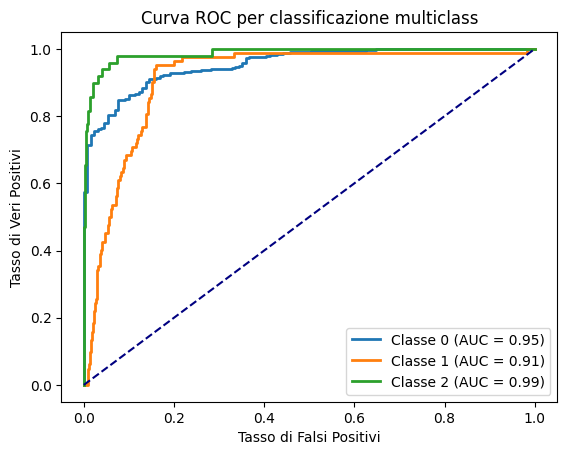

In [ ]:
# binarize the y_true labels to adapt them to the format required
# for the ROC curve. This is necessary for multiclass classification problems
y_true = np.argmax(y_test_completo, axis=1)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

# predictions of the NN_downsampled network
prediction = nn_on_pca_downsampled.predict(X_test_completo)

# list of colors for each class
colors = ['tab:blue', 'tab:orange', 'tab:green']

fpr = dict()
tpr = dict()
roc_auc = dict()

# compute the ROC curve for each class
for i in range(3):  # For the three classes
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], prediction[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()

# add the ROC curve of each class to the plot
for i in range(3):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2, label=f'Classe {i} (AUC = {roc_auc[i]:.2f})')

# draw the diagonal
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')

plt.xlabel('Tasso di Falsi Positivi')
plt.ylabel('Tasso di Veri Positivi')
plt.title('Curva ROC per classificazione multiclass')
plt.legend(loc='lower right')
plt.show()

### Prediction of the removed data only
Here we predict only the class 0 samples that were removed during the dataset downsampling phase. We check whether the model is able to classify all or almost all of them as belonging to class 0. Although the test of the network on the full test set already reports the predictions for these samples, it is still useful to view their results separately.  

In [ ]:
y_data_removed= keras.utils.to_categorical(df_scaled_data_removed["fetal_health"], num_classes=3)

classificatin_report_nn(nn_on_pca_downsampled, pca_data_removed, y_data_removed)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
              precision    recall  f1-score   support

      Normal       1.00      0.85      0.92      1420
     Suspect       0.00      0.00      0.00         0
Pathological       0.00      0.00      0.00         0

    accuracy                           0.85      1420
   macro avg       0.33      0.28      0.31      1420
weighted avg       1.00      0.85      0.92      1420

matrice di confusione

[[1207  196   17]
 [   0    0    0]
 [   0    0    0]]


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Plots of the data distribution

We compare
- the downsampled dataset and how it is labelled

- the classification of the downsampled test set

- the classification of the data removed during the dataset downsampling phase

[0 1 2]
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


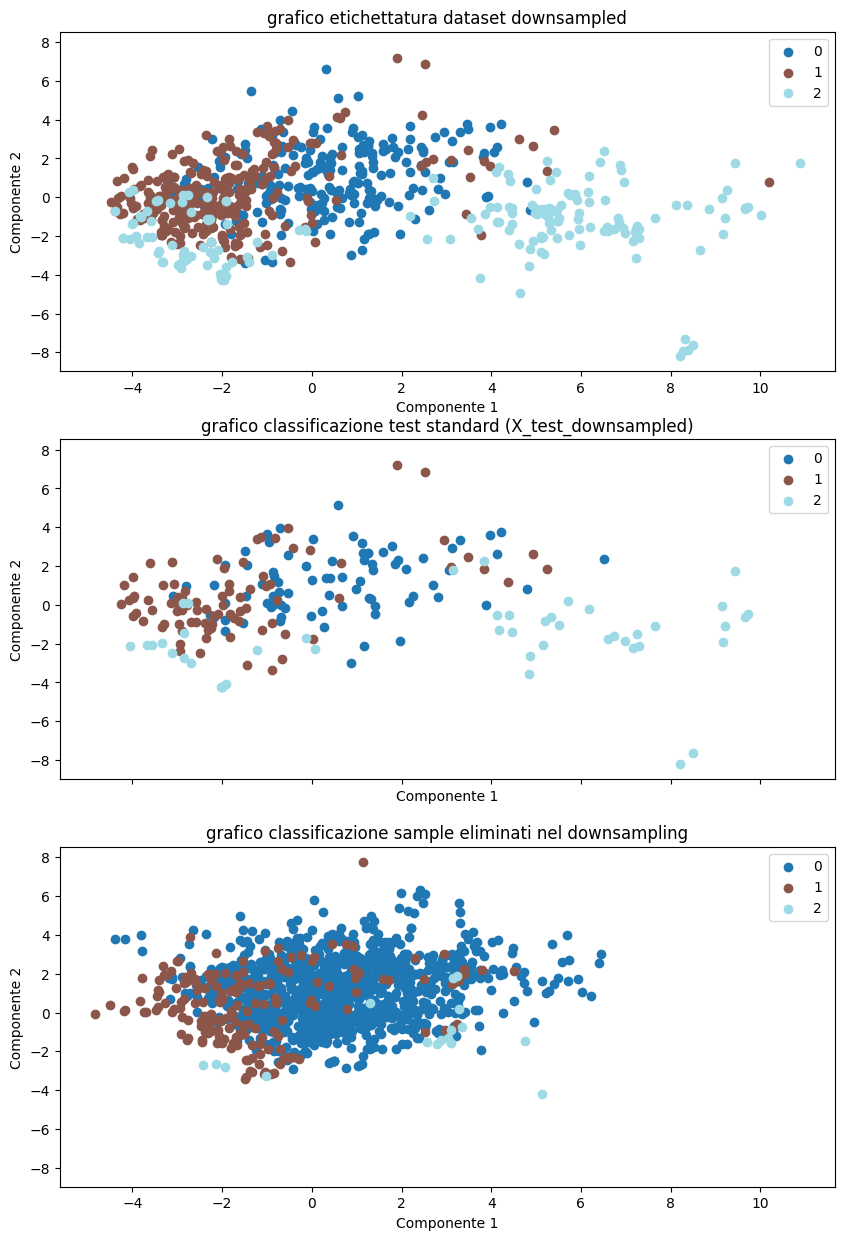

In [ ]:
# create a label-->color code map
unique_labels = np.unique(df_scaled_downsampled["fetal_health"])
print(unique_labels)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))
label_to_color = dict(zip(unique_labels, colors))


# plot of the downsampled dataset labelling
fig, (ax, ax1, ax2) =  plt.subplots(3, 1, figsize=(10, 15), sharex=True, sharey=True)
for label in unique_labels:
    mask = (df_scaled_downsampled["fetal_health"] == label).values
    ax.scatter(pca_data[mask, 0], pca_data[mask, 1], color=label_to_color[label], label=label)
ax.set_title("grafico etichettatura dataset downsampled")

# plot of the classification of the standard test samples (X_test_downsampled)
prediction_test_downsampled = nn_on_pca_downsampled.predict(X_test_downsampled)
y_pred_test_downsampled = np.argmax(prediction_test_downsampled, axis=1)

for label in np.unique(y_pred_test_downsampled):
    mask = (y_pred_test_downsampled == label)
    ax1.scatter(X_test_downsampled[mask, 0], X_test_downsampled[mask, 1], color=label_to_color[label], label=label)
ax1.set_title("grafico classificazione test standard (X_test_downsampled)")

# plot of the classification of the samples removed during the downsampling phase
prediction_data_removed = nn_on_pca_downsampled.predict(pca_data_removed)
y_pred_data_removed = np.argmax(prediction_data_removed, axis=1)

for label in np.unique(y_pred_data_removed):
    mask = (y_pred_data_removed == label)
    ax2.scatter(pca_data_removed[mask, 0], pca_data_removed[mask, 1], color=label_to_color[label], label=label)
ax2.set_title("grafico classificazione sample eliminati nel downsampling")

ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.tick_params(labelbottom=True)
ax1.legend()

ax2.set_xlabel('Componente 1')
ax2.set_ylabel('Componente 2')
ax2.tick_params(labelbottom=True)
ax2.legend()


ax1.set_xlabel('Componente 1')
ax1.set_ylabel('Componente 2')
ax.legend()


plt.show()

##NN_PCA

We check how a network behaves when trained on the whole dataset, transformed with PCA, but using the class weighting technique.

We therefore compare the downsampling technique and the class weighting technique in the context of imbalanced ML problems.

### Splitting of the original dataset (transformed with PCA)

In [ ]:
X_train_weighted_class, X_test_weighted_class, y_train_weighted_class, y_test_weighted_class = train_test_split(pca_data_originale, df_originale["fetal_health"], test_size=0.3, random_state=42)

# one-hot encode the target variables
y_train_weighted_class = keras.utils.to_categorical(y_train_weighted_class)
y_test_weighted_class = keras.utils.to_categorical(y_test_weighted_class)

### Network creation

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


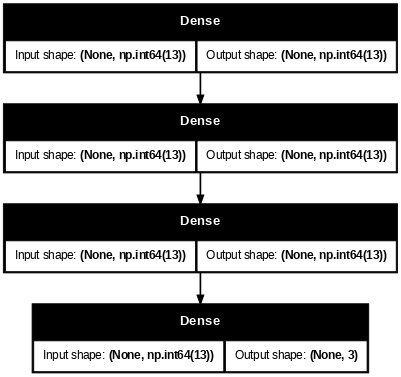

In [ ]:
nn_on_df_originale_pca = crea_rete_neurale(input_shape=n_components, num_classi=3, metrica=[recall_suspect, recall_pathologic])

keras.utils.plot_model(nn_on_df_originale_pca, show_shapes=True, dpi=60)

### Class weight computation

In [ ]:
# retrieve the label values from the one-hot encoding
y_train_labels = np.argmax(y_train_weighted_class, axis=1)

# compute the class weights
class_weights = compute_class_weight('balanced', classes=np.sort(df_originale["fetal_health"].unique()), y=y_train_labels)
class_weight_dict = dict(enumerate(class_weights))
print(f"Pesi delle classi: {class_weight_dict}")

Pesi delle classi: {0: np.float64(0.42795513373597927), 1: np.float64(2.556701030927835), 2: np.float64(3.674074074074074)}


Class 0 has a lower weight because it is the majority class.

### Network training

In [ ]:
history_nn_on_df_originale_pca = nn_on_df_originale_pca.fit(X_train_weighted_class, y_train_weighted_class, epochs=200, batch_size=20, class_weight=class_weight_dict, verbose=1)

Epoch 1/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.1339 - recall_pathologic: 0.0971 - recall_suspect: 0.8734
Epoch 2/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1168 - recall_pathologic: 0.5939 - recall_suspect: 0.8158
Epoch 3/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0487 - recall_pathologic: 0.5214 - recall_suspect: 0.8866
Epoch 4/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0259 - recall_pathologic: 0.6760 - recall_suspect: 0.8353
Epoch 5/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9879 - recall_pathologic: 0.5702 - recall_suspect: 0.8279
Epoch 6/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9579 - recall_pathologic: 0.6424 - recall_suspect: 0.8070
Epoch 7/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8826 - recall_pathologic: 0.6157 - recall_suspect: 0.8721
Epoch 8/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8934 - recall_pathologic: 0.6664 - recall_suspect: 0.7595
Epoch 9/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/st

dict_keys(['loss', 'recall_pathologic', 'recall_suspect'])


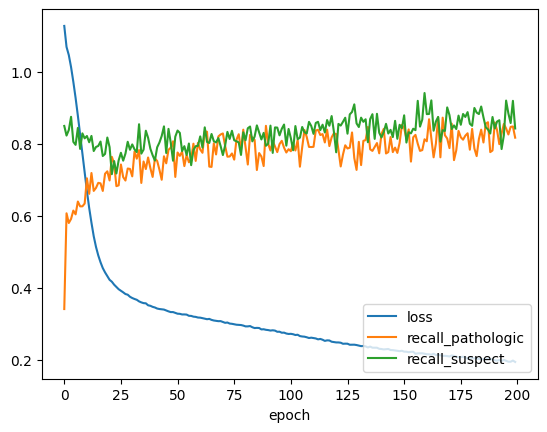

In [ ]:
plot_metriche_training(history_nn_on_df_originale_pca)

### Network test

In [ ]:
classificatin_report_nn(nn_on_df_originale_pca, X_test_weighted_class, y_test_weighted_class)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

      Normal       0.98      0.84      0.91       496
     Suspect       0.53      0.83      0.64       101
Pathological       0.76      0.93      0.84        41

    accuracy                           0.85       638
   macro avg       0.75      0.87      0.80       638
weighted avg       0.89      0.85      0.86       638

matrice di confusione

[[419  74   3]
 [  8  84   9]
 [  1   2  38]]


##NN_original

We check the behaviour of a network trained on the whole original dataset, i.e. not transformed with PCA. The goal is to verify whether PCA actually leads to better generalization of the data by the model.

### Splitting of the original dataset (no PCA)

In [ ]:
X_train_df_originale, X_test_df_originale, y_train_df_originale, y_test_df_originale = train_test_split(df_originale_scaled[variabili_numeriche], df_originale["fetal_health"], test_size=0.3, random_state=42)

# one-hot encode the target variables
y_train_df_originale = keras.utils.to_categorical(y_train_df_originale)
y_test_df_originale = keras.utils.to_categorical(y_test_df_originale)

### Network creation

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


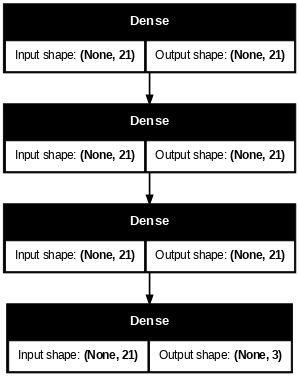

In [ ]:
nn_data_orig = crea_rete_neurale(input_shape=21, num_classi=3, metrica=[recall_suspect, recall_pathologic])

keras.utils.plot_model(nn_data_orig, show_shapes=True, dpi=60)

### Class weight computation

In [ ]:
# retrieve the label values from the one-hot encoding
y_train_labels = np.argmax(y_train_df_originale, axis=1)

# compute the class weights
class_weights = compute_class_weight('balanced', classes=np.sort(df_originale["fetal_health"].unique()), y=y_train_labels)
class_weight_dict = dict(enumerate(class_weights))
print(f"Pesi delle classi: {class_weight_dict}")

Pesi delle classi: {0: np.float64(0.42795513373597927), 1: np.float64(2.556701030927835), 2: np.float64(3.674074074074074)}


### Network training

In [ ]:
history_nn_data_clean = nn_data_orig.fit(X_train_df_originale, y_train_df_originale, epochs=200, batch_size=20, class_weight=class_weight_dict, verbose=1)

Epoch 1/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.1630 - recall_pathologic: 0.0745 - recall_suspect: 0.0284
Epoch 2/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0658 - recall_pathologic: 0.3481 - recall_suspect: 0.3543
Epoch 3/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9650 - recall_pathologic: 0.6762 - recall_suspect: 0.1068
Epoch 4/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9824 - recall_pathologic: 0.6634 - recall_suspect: 0.8467
Epoch 5/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8811 - recall_pathologic: 0.6327 - recall_suspect: 0.8428
Epoch 6/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8064 - recall_pathologic: 0.7668 - recall_suspect: 0.6524
Epoch 7/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7019 - recall_pathologic: 0.6330 - recall_suspect: 0.8419
Epoch 8/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6517 - recall_pathologic: 0.6861 - recall_suspect: 0.7069
Epoch 9/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/st

dict_keys(['loss', 'recall_pathologic', 'recall_suspect'])


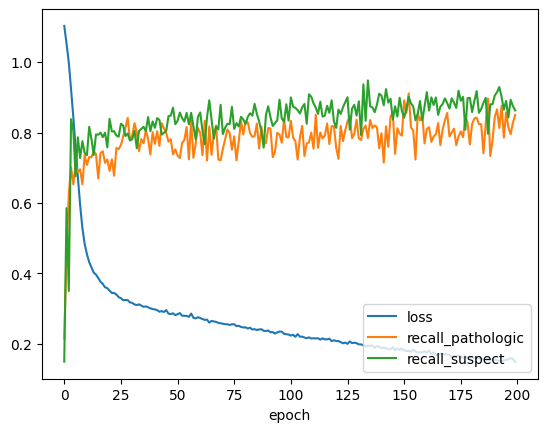

In [ ]:
plot_metriche_training(history_nn_data_clean)

### Network test

In [ ]:
classificatin_report_nn(nn_data_orig, X_test_df_originale, y_test_df_originale)

NameError: name 'classificatin_report_nn' is not defined

#Decision tree

## Helper functions for the trees

In [ ]:
def classificatin_report_tree(model, X_test, y_test):

  prediction = model.predict(X_test)

  # Generate the classification report
  print(classification_report(y_test, prediction, target_names=["Normal", "Suspect", "Pathological"]))

  cm = confusion_matrix(y_test, prediction)
  print("matrice di confusione\n")
  print(cm)

  # compute the F2-score for each class
  # the F2-score puts more emphasis on recall than the F1-score
  #print("\nF2-score per ogni classe\n")
  #for class_idx in np.sort(df_originale["fetal_health"].unique()):
  #  print(f"F2-score per la classe {class_idx}: {fbeta_score(y_test, prediction, beta = 2, average = 'macro', labels=[class_idx])}")

## Definition of preliminary variables

In [ ]:
#bring the y back to the original format
y_train_df_originale = np.argmax(y_train_df_originale, axis=1)
y_test_df_originale = np.argmax(y_test_df_originale, axis=1)

# variables for the tree plots
target_name = "fetal_health"
feature_names = variabili_numeriche
class_names = ["normal", "suspect", "pathological"]

## Best hyperparameter for pruning the tree

### Computing the possible values of the complexity parameter

In [ ]:
model = DecisionTreeClassifier(random_state=42, class_weight="balanced")
model = model.fit(X_train_df_originale, y_train_df_originale)

aa = model.cost_complexity_pruning_path(X_train_df_originale, y_train_df_originale)
ccp_alphas = aa.ccp_alphas

In [ ]:
ccp_alphas

array([0.00000000e+00, 6.38609735e-19, 6.38609735e-19, 6.38609735e-19,
       6.38609735e-19, 7.66331682e-19, 1.27721947e-18, 1.27721947e-18,
       4.11193713e-18, 1.56253611e-17, 9.25185854e-17, 3.04616844e-16,
       2.76052450e-04, 2.76052450e-04, 2.79798545e-04, 2.82127239e-04,
       2.87146083e-04, 4.22188773e-04, 4.92296802e-04, 4.92732200e-04,
       5.09466225e-04, 5.15198351e-04, 5.30785563e-04, 5.44810678e-04,
       5.52104900e-04, 5.52104900e-04, 5.64705882e-04, 7.17185648e-04,
       7.39206324e-04, 8.48524782e-04, 8.52303091e-04, 8.61883215e-04,
       8.61883215e-04, 9.33053417e-04, 9.40512579e-04, 9.85464400e-04,
       1.00433008e-03, 1.13222648e-03, 1.13648259e-03, 1.14311244e-03,
       1.30052187e-03, 1.33946229e-03, 1.36688683e-03, 1.56955072e-03,
       1.56955072e-03, 1.63740077e-03, 1.70111864e-03, 1.70162918e-03,
       1.82501510e-03, 1.91803251e-03, 2.02634245e-03, 2.05732109e-03,
       2.24322236e-03, 2.28259038e-03, 2.38083102e-03, 2.41864023e-03,
      

### Accuracy vs. complexity parameter plot

alpha con accuretezza superiore a 0.8: 0.0
alpha con accuretezza superiore a 0.8: 6.38609735188461e-19
alpha con accuretezza superiore a 0.8: 6.38609735188461e-19
alpha con accuretezza superiore a 0.8: 6.38609735188461e-19
alpha con accuretezza superiore a 0.8: 6.38609735188461e-19
alpha con accuretezza superiore a 0.8: 7.663316822261531e-19
alpha con accuretezza superiore a 0.8: 1.277219470376922e-18
alpha con accuretezza superiore a 0.8: 1.277219470376922e-18
alpha con accuretezza superiore a 0.8: 4.111937128241257e-18
alpha con accuretezza superiore a 0.8: 1.562536108731677e-17
alpha con accuretezza superiore a 0.8: 9.251858538542815e-17
alpha con accuretezza superiore a 0.8: 3.0461684368489554e-16
alpha con accuretezza superiore a 0.8: 0.0002760524499654895
alpha con accuretezza superiore a 0.8: 0.0002760524499654895
alpha con accuretezza superiore a 0.8: 0.00027979854504756095
alpha con accuretezza superiore a 0.8: 0.0002821272393849557
alpha con accuretezza superiore a 0.8: 0.000

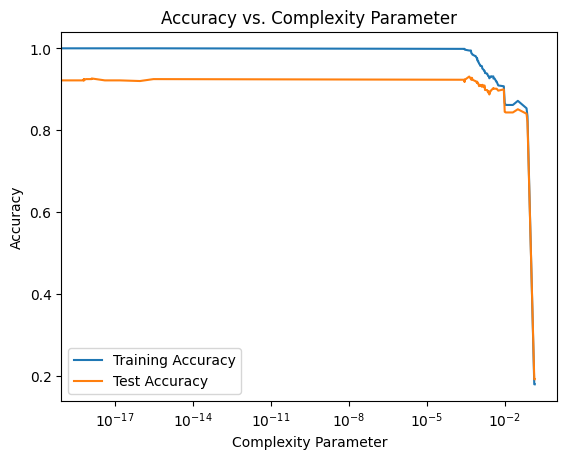

In [ ]:
# train the decision tree with different complexity values
train_accuracy = []
test_accuracy = []

# lower bound for the accuracy
threshold_acc = 0.80

for complexity in ccp_alphas:
    clf = DecisionTreeClassifier(ccp_alpha=complexity, class_weight="balanced")
    clf.fit(X_train_df_originale, y_train_df_originale)
    # print to the console the values of the complexity parameter
    # that yield a decision tree with accuracy above
    # 80%
    if(clf.score(X_test_df_originale, y_test_df_originale) >= threshold_acc):
      print(f"alpha con accuretezza superiore a {threshold_acc}: {complexity}")
    train_accuracy.append(clf.score(X_train_df_originale, y_train_df_originale))
    test_accuracy.append(clf.score(X_test_df_originale, y_test_df_originale))


# plot the accuracy of the model as a function of the complexity parameter
plt.plot(ccp_alphas, train_accuracy, label='Training Accuracy')
plt.plot(ccp_alphas, test_accuracy, label='Test Accuracy')
plt.xlabel('Complexity Parameter')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Complexity Parameter')
plt.xscale('log')
plt.legend()
plt.show()

### Error vs. complexity parameter plot

alpha con errore sotto la soglia: 0.0
alpha con errore sotto la soglia: 6.38609735188461e-19
alpha con errore sotto la soglia: 6.38609735188461e-19
alpha con errore sotto la soglia: 6.38609735188461e-19
alpha con errore sotto la soglia: 6.38609735188461e-19
alpha con errore sotto la soglia: 7.663316822261531e-19
alpha con errore sotto la soglia: 1.277219470376922e-18
alpha con errore sotto la soglia: 1.277219470376922e-18
alpha con errore sotto la soglia: 4.111937128241257e-18
alpha con errore sotto la soglia: 1.562536108731677e-17
alpha con errore sotto la soglia: 9.251858538542815e-17
alpha con errore sotto la soglia: 3.0461684368489554e-16
alpha con errore sotto la soglia: 0.0002760524499654895
alpha con errore sotto la soglia: 0.0002760524499654895
alpha con errore sotto la soglia: 0.00027979854504756095
alpha con errore sotto la soglia: 0.0002821272393849557
alpha con errore sotto la soglia: 0.0002871460826193956
alpha con errore sotto la soglia: 0.0004221887734498296
alpha con er

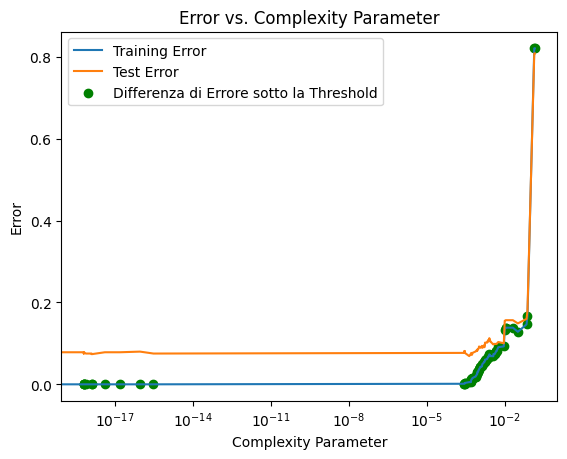

In [ ]:
train_error = [1 - acc for acc in train_accuracy]
test_error = [1 - acc for acc in test_accuracy]
threshold_err = 1-threshold_acc

# difference between the error computed during training and
# the error computed during testing
error_diffs = [abs(train_err - test_err) for train_err, test_err in zip(train_error, test_error)]

for i, error_diff in enumerate(error_diffs):
    if error_diff < threshold_err :
        print(f"alpha con errore sotto la soglia: {ccp_alphas[i]}")

# show in the plot the points such that the error difference is below the threshold
green_points = [error_diff < threshold_err ##
                 for error_diff, train_err, test_err in zip(error_diffs, train_error, test_error)]

# show the errors of the model as a function of the complexity parameter
plt.plot(ccp_alphas, train_error, label='Training Error')
plt.plot(ccp_alphas, test_error, label='Test Error')
plt.scatter([ccp_alphas[i] for i, is_green in enumerate(green_points) if is_green],
            [train_error[i] for i, is_green in enumerate(green_points) if is_green],
            color='green', label='Differenza di Errore sotto la Threshold')  # Green points
plt.xlabel('Complexity Parameter')
plt.ylabel('Error')
plt.title('Error vs. Complexity Parameter')
plt.xscale('log')
plt.legend()
plt.show()

## Tree defined with a given optimal complexity parameter (T1)

We choose a complexity parameter that yields a tree pruned enough to be easily interpretable, while still having an acceptable error rate.

In [ ]:
complex_param1 = 0.009017265771584636

[]

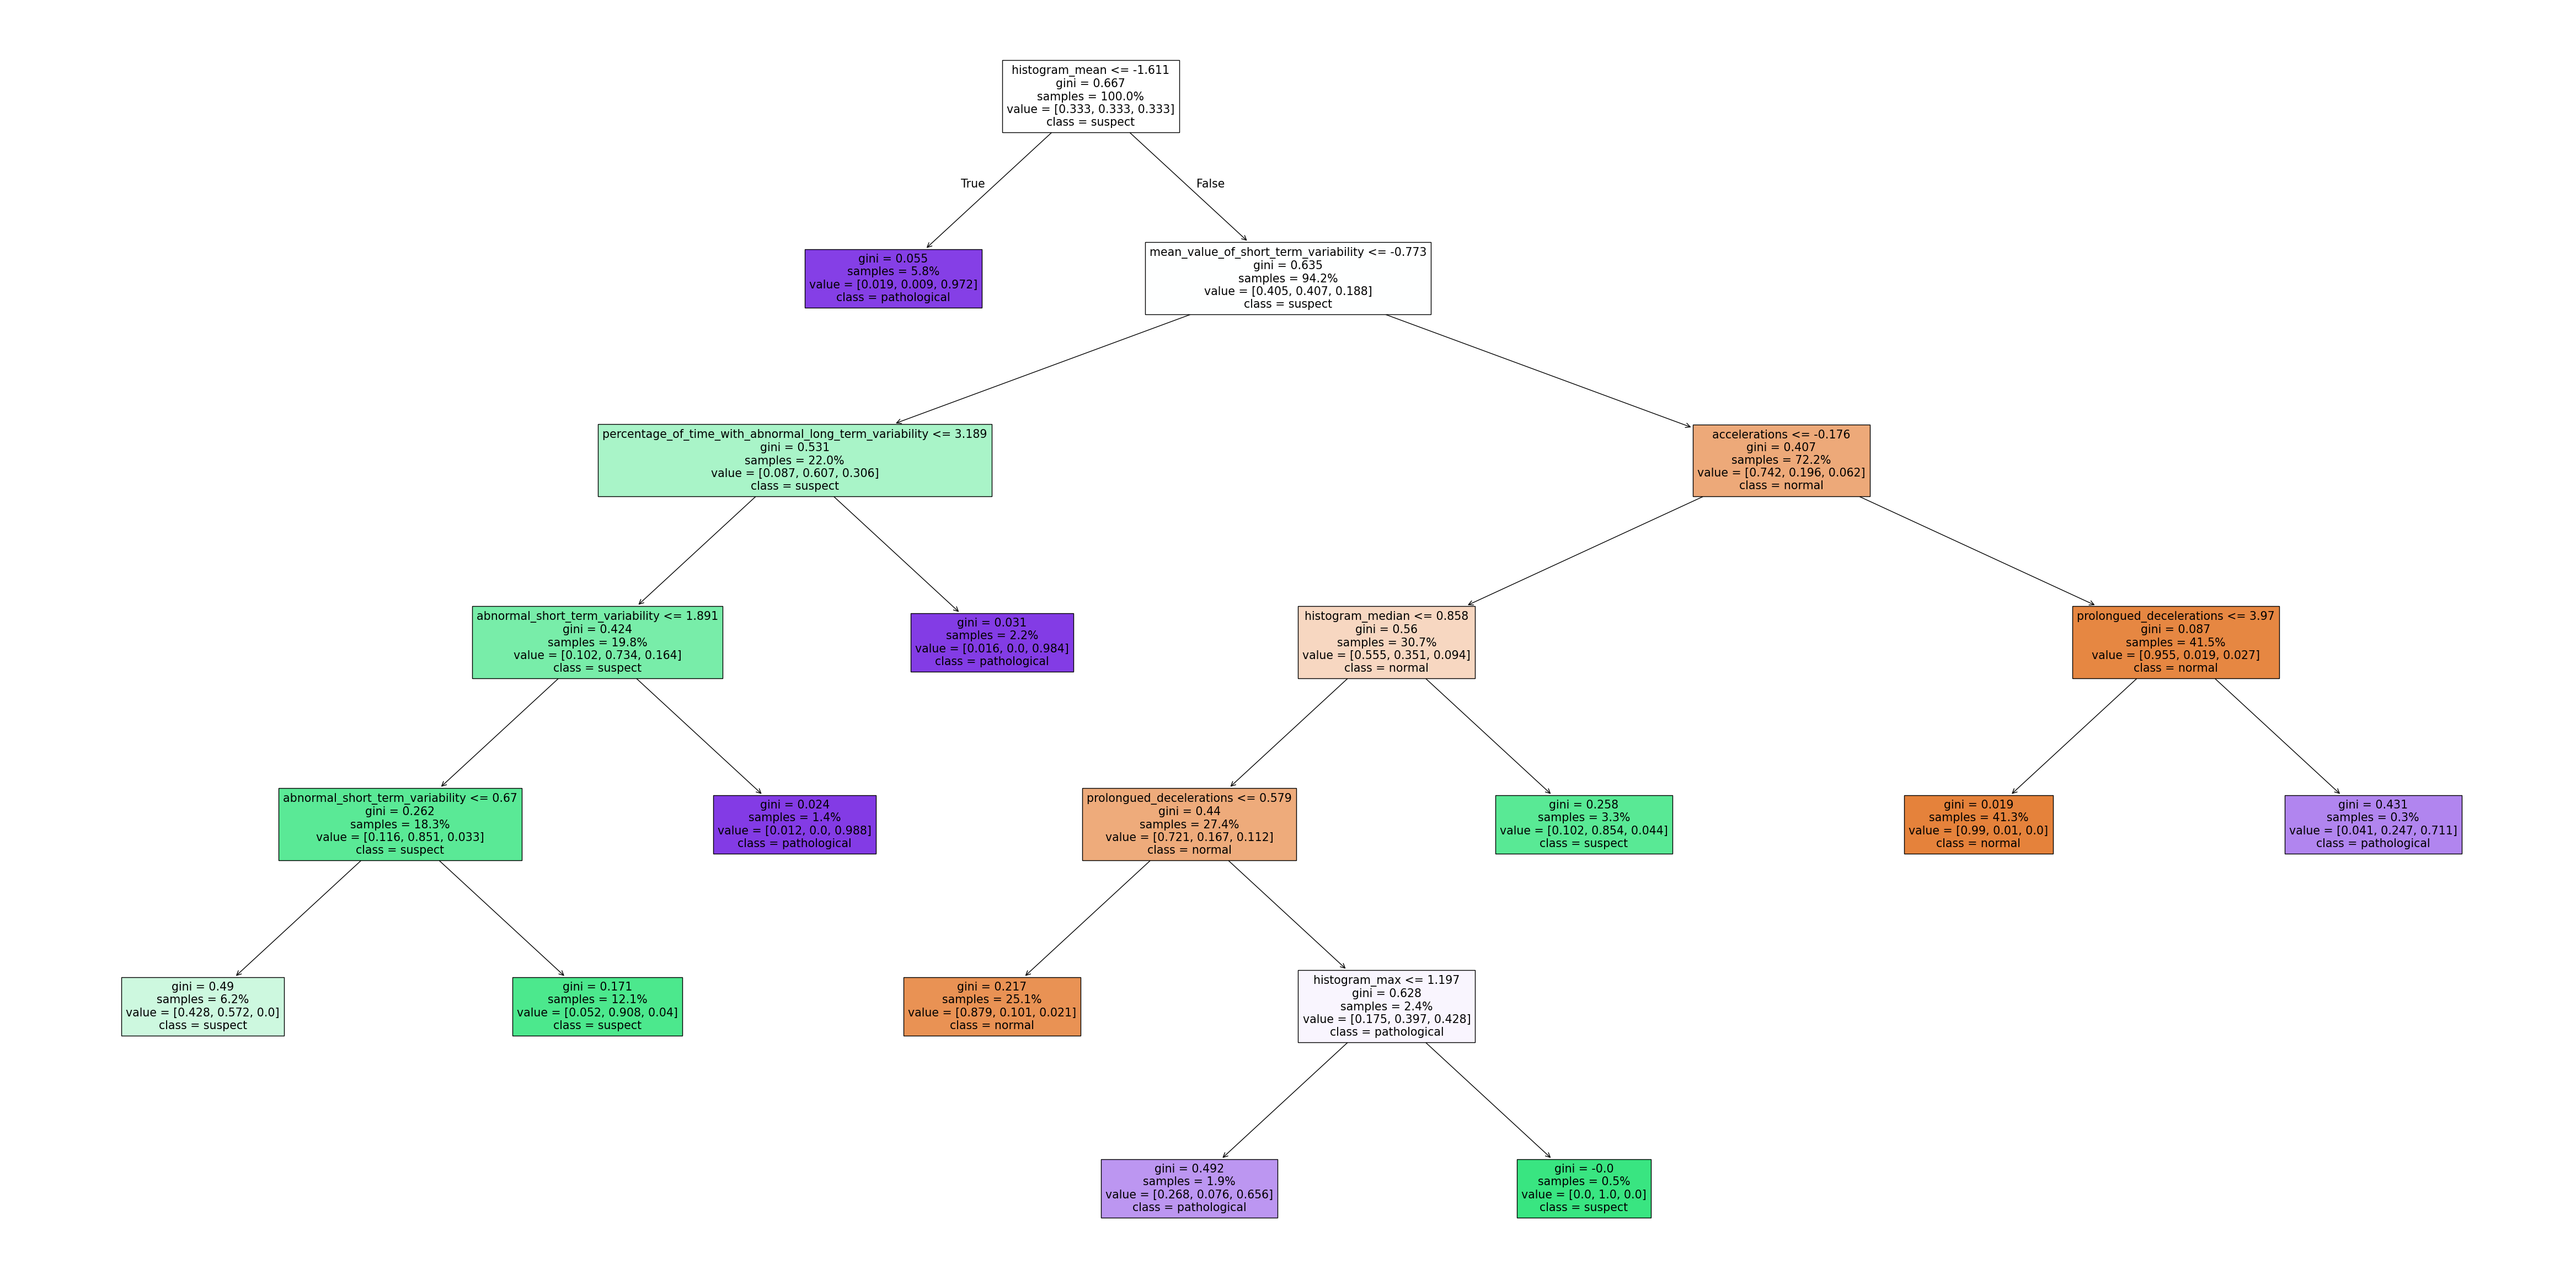

In [ ]:
model_best_pruning1 = DecisionTreeClassifier(random_state=42, ccp_alpha = complex_param1, class_weight="balanced")
model_best_pruning1 = model_best_pruning1.fit(X_train_df_originale, y_train_df_originale)

# Display the decision tree
fig, ax = plt.subplots(figsize=(60, 30))
plot_tree(model_best_pruning1, filled=True, ax=ax, feature_names=feature_names,class_names=class_names, impurity=True, proportion=True)
plt.plot()

In [ ]:
classificatin_report_tree(model_best_pruning1, X_test_df_originale, y_test_df_originale)

              precision    recall  f1-score   support

      Normal       0.99      0.82      0.90       496
     Suspect       0.56      0.91      0.69       101
Pathological       0.67      1.00      0.80        41

    accuracy                           0.85       638
   macro avg       0.74      0.91      0.80       638
weighted avg       0.90      0.85      0.86       638

matrice di confusione

[[407  72  17]
 [  6  92   3]
 [  0   0  41]]


## Most important features for T1

In [ ]:
model_best_pruning1.feature_importances_

array([0.        , 0.05128534, 0.        , 0.        , 0.        ,
       0.        , 0.05665235, 0.14835995, 0.25343738, 0.13891203,
       0.        , 0.        , 0.        , 0.02016296, 0.        ,
       0.        , 0.        , 0.26405442, 0.06713556, 0.        ,
       0.        ])

In [ ]:
len(model_best_pruning1.feature_importances_)

21

In [ ]:
df_feature_importance = pd.DataFrame(model_best_pruning1.feature_importances_, index=feature_names, columns=["importance"])
df_feature_importance.sort_values(by="importance", ascending=False)

,importance
histogram_mean,0.264054
mean_value_of_short_term_variability,0.253437
abnormal_short_term_variability,0.148360
percentage_of_time_with_abnormal_long_term_variability,0.138912
histogram_median,0.067136
prolongued_decelerations,0.056652
accelerations,0.051285
histogram_max,0.020163
baseline value,0.000000
histogram_variance,0.000000


## Tree built from another optimal complexity parameter (T2)


Here we study a tree created with a larger complexity parameter, which will therefore define a smaller tree.

In [ ]:
complex_param2 = 0.01082758511624278

[]

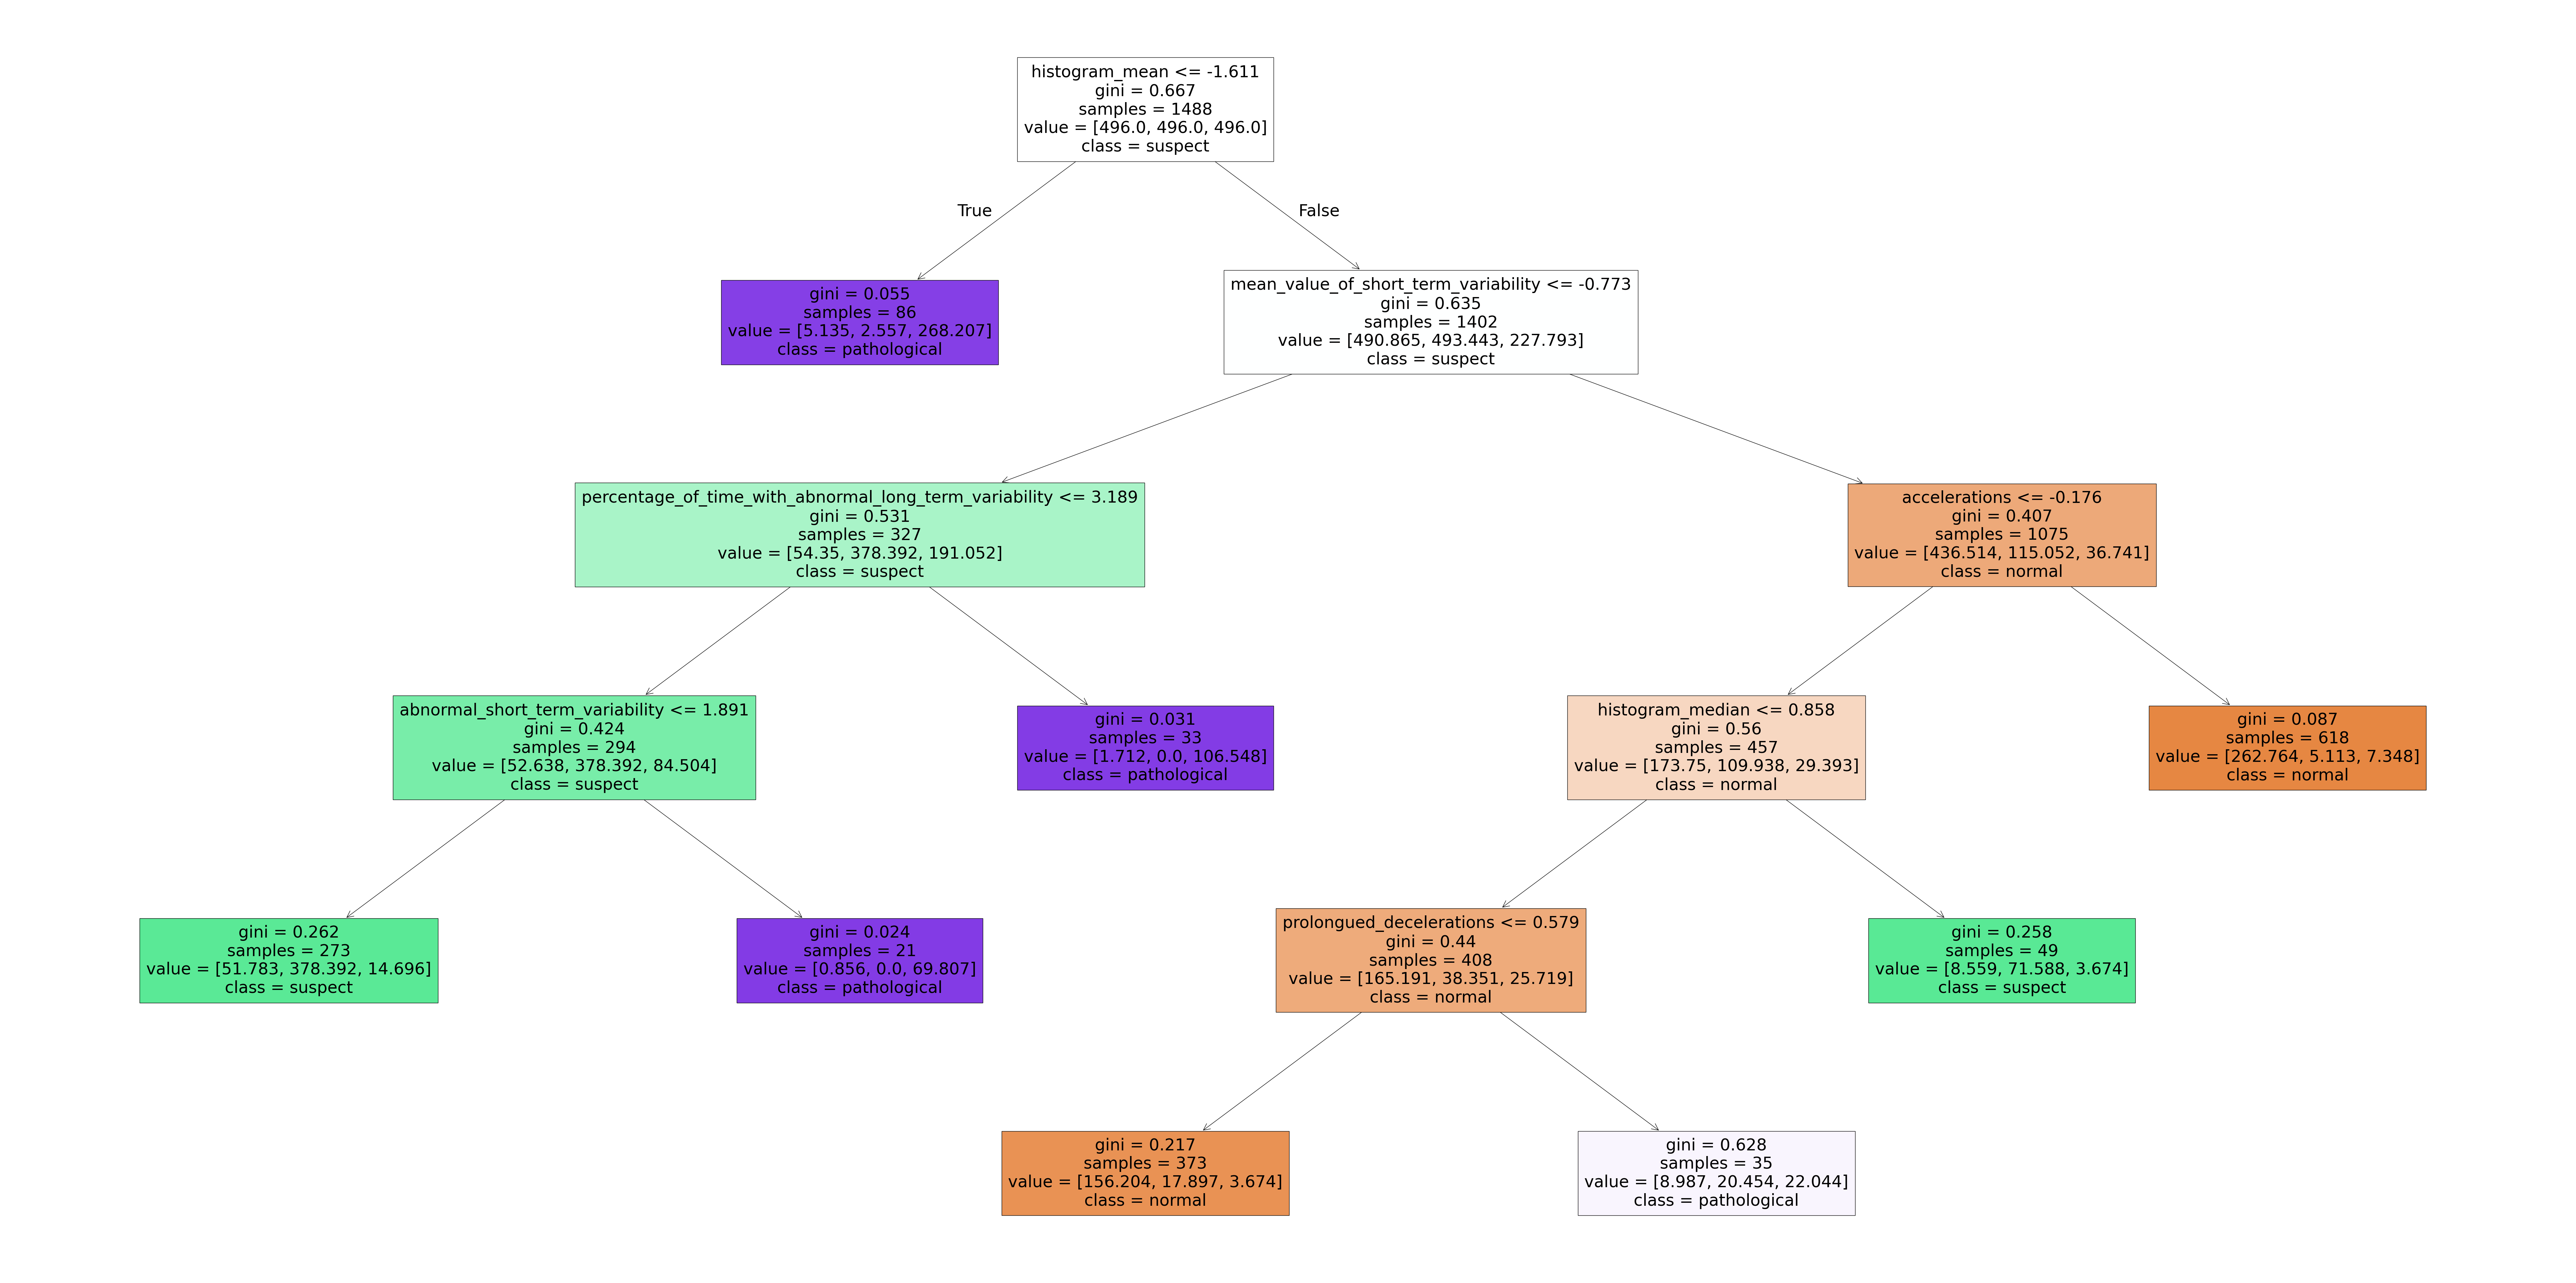

In [ ]:
model_best_pruning2 = DecisionTreeClassifier(random_state=42, ccp_alpha = complex_param2 , class_weight="balanced")
model_best_pruning2 = model_best_pruning2.fit(X_train_df_originale, y_train_df_originale)

# display the decision tree
fig, ax = plt.subplots(figsize=(100, 50))
plot_tree(model_best_pruning2, filled=True, ax=ax, feature_names=feature_names,class_names=class_names, impurity=True)
plt.plot()

In [ ]:
classificatin_report_tree(model_best_pruning2, X_test_df_originale, y_test_df_originale)

              precision    recall  f1-score   support

      Normal       0.98      0.82      0.89       496
     Suspect       0.56      0.90      0.69       101
Pathological       0.66      0.98      0.78        41

    accuracy                           0.84       638
   macro avg       0.73      0.90      0.79       638
weighted avg       0.89      0.84      0.85       638

matrice di confusione

[[407  72  17]
 [  6  91   4]
 [  1   0  40]]


# Evaluation of the NNs

## Helper functions

In [ ]:
def intervalli_confidenza_f1_score(f1_scores_per_class) :

  # compute the confidence intervals for the F1-score of each class
  confidence_intervals_f1 = []
  for class_scores in f1_scores_per_class:
      confidence_interval = st.t.interval(confidence=0.95, df=len(class_scores)-1, loc=np.mean(class_scores), scale=st.sem(class_scores))
      confidence_intervals_f1.append(confidence_interval)

  # print to the console the confidence intervals for the F1-score
  for class_idx, interval in enumerate(confidence_intervals_f1):
      print(f"Intervallo di confidenza F1-score per la classe {class_idx}: {interval}")

### Evaluation of NN_downsampled

In [ ]:
rkf = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)
rkf.get_n_splits()

10

In [ ]:
accuracy_repeated_cv = []
f1_scores_per_class = [[], [], []]  # One list for each class
for n_fold, (train_idx, valid_idx) in enumerate(rkf.split(pca_data)):

        # definition of the downsampled dataset
        downsampled_majority_it = df_majority.sample(n=min_sample_number, random_state=42)
        df_scaled_downsampled_it = pd.concat([downsampled_majority_it, df_minority_1, df_minority_2])
        pca_data_it = pca.transform(df_scaled_downsampled_it[variabili_numeriche])
        pca_data_df_it = pd.DataFrame(pca_data_it)

        # definition of the dataframe of the removed samples belonging to the majority class
        df_scaled_data_removed_it = df_majority.drop(downsampled_majority_it.index)
        pca_data_removed_it = pca.transform(df_scaled_data_removed_it[variabili_numeriche])

        # splitting of the downsampled dataset
        X_train, X_valid = pca_data_df_it.iloc[train_idx], pca_data_df_it.iloc[valid_idx]
        y_train, y_valid = df_scaled_downsampled_it["fetal_health"].iloc[train_idx], df_scaled_downsampled_it["fetal_health"].iloc[valid_idx]

        # add to the test set the samples removed by the downsampling,
        # i.e. the samples in pca_data_removed_it
        X_valid = np.concatenate((X_valid, pca_data_removed_it))
        y_valid = np.concatenate((y_valid, df_scaled_data_removed_it["fetal_health"]))

        # one-hot encode y_train
        y_train_encoded = keras.utils.to_categorical(y_train, num_classes=3)

        # create the network
        model = crea_rete_neurale(input_shape=n_components, num_classi=3, metrica=[recall_suspect, recall_pathologic])

        # model training
        model.fit(X_train, y_train_encoded, epochs=100, batch_size=5, verbose=1)

        # model test
        y_pred_valid = model.predict(X_valid)

        # convert the predictions (probabilities) into classes
        y_pred_valid_labels = np.argmax(y_pred_valid, axis=1)

        # store the accuracy of the model
        accuracy_repeated_cv.append(accuracy_score(y_valid,y_pred_valid_labels))

        # compute the F1-score for each class
        for class_idx in np.sort(df_originale["fetal_health"].unique()):
          f1 = f1_score(y_valid, y_pred_valid_labels, average='macro', labels=[class_idx])
          f1_scores_per_class[class_idx].append(f1)

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.0969 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9693
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0582 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9487
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0506 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9135
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0071 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9597
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9768 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.7425
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8737 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9079
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8577 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8763
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7965 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8759
Epoch 9/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 1.1477 - recall_pathologic: 0.1949 - recall_suspect: 0.0584
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0481 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9401
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0408 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8909
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0036 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9701
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9696 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8866
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9027 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8816
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8523 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8813
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7807 - recall_pathologic: 0.0133 - recall_suspect: 0.9268
Epoch 9/100
113/113 

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (11 outputs left out)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.1882 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.0000e+00
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0671 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.4525
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0582 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.8361
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0297 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9441
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9816 - recall_pathologic: 4.7282e-04 - recall_suspect: 0.8976
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9230 - recall_pathologic: 0.1493 - recall_suspect: 0.8748
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8523 - recall_pathologic: 0.4424 - recall_suspect: 0.8307
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7431 - recall_pathologic: 0.4436 - recall_suspect: 0.8840
Epoch 9/100
113/113 

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2084 - recall_pathologic: 0.7432 - recall_suspect: 0.0606
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0673 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9404
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0511 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9453
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0361 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9372
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9981 - recall_pathologic: 0.0328 - recall_suspect: 0.9542
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9380 - recall_pathologic: 0.4776 - recall_suspect: 0.9552
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8783 - recall_pathologic: 0.6103 - recall_suspect: 0.8910
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8026 - recall_pathologic: 0.6399 - recall_suspect: 0.9179
Epoch 9/100
113/113 ━━━━━━━━━━━━

In [ ]:
accuracy_repeated_cv

[0.8418693982074263,
 0.8609865470852018,
 0.8629083920563742,
 0.8705957719410634,
 0.8558616271620756,
 0.8457106274007683,
 0.8635490070467648,
 0.8398462524023063,
 0.8641896220371557,
 0.8673926969891096]

#### Confidence interval for the accuracy

In [ ]:
st.t.interval(confidence=0.90, df=len(accuracy_repeated_cv)-1, loc=np.mean(accuracy_repeated_cv), scale=st.sem(accuracy_repeated_cv))

(0.850913563588415, 0.863668424877234)

#### Confidence intervals for the F1-scores

In [ ]:
intervalli_confidenza_f1_score(f1_scores_per_class)

Intervallo di confidenza F1-score per la classe 0: (0.9164062003305979, 0.9262758277109209)
Intervallo di confidenza F1-score per la classe 1: (0.3251900522701795, 0.35820673959650684)
Intervallo di confidenza F1-score per la classe 2: (0.6489576620068589, 0.6924783260706051)


### Evaluation of NN_PCA

In [ ]:
pca_data_originale_df = pca_data_df_it = pd.DataFrame(pca_data_originale)

class_weights = compute_class_weight('balanced', classes=np.sort(df_originale["fetal_health"].unique()), y=y_train_labels)
class_weight_dict = dict(enumerate(class_weights))
print(f"Peso delle classi: {class_weight_dict}")

Peso delle classi: {0: 0.42795513373597927, 1: 2.556701030927835, 2: 3.674074074074074}


In [ ]:
rkf.split(pca_data_originale_df)
rkf.get_n_splits()

10

In [ ]:
accuracy_repeated_nn_pca_data_orig = []
f1_scores_per_class_pca_data_orig = [[],[],[]]
for n_fold, (train_idx, valid_idx) in enumerate(rkf.split(pca_data_originale_df)):
        # splitting of the dataset
        X_train, X_valid = pca_data_originale_df.iloc[train_idx], pca_data_originale_df.iloc[valid_idx]
        y_train, y_valid = df_originale["fetal_health"].iloc[train_idx], df_originale["fetal_health"].iloc[valid_idx]

        # create the network
        model = crea_rete_neurale(input_shape=n_components, num_classi=3, metrica=[recall_suspect, recall_pathologic])

        # one-hot encode y_train
        y_train_encoded = keras.utils.to_categorical(y_train, num_classes=3)

        # model training
        model.fit(X_train, y_train_encoded, epochs=50, batch_size=20, class_weight=class_weight_dict, verbose=1)

        # model test
        y_pred_valid = model.predict(X_valid)
        y_pred_valid_labels = np.argmax(y_pred_valid, axis=1)

        # compute accuracy
        accuracy_repeated_nn_pca_data_orig.append(accuracy_score(y_valid,y_pred_valid_labels))

        # compute f1 score
        for class_idx in np.sort(df_originale["fetal_health"].unique()):
          f1 = f1_score(y_valid, y_pred_valid_labels, average='macro', labels=[class_idx])
          f1_scores_per_class_pca_data_orig[class_idx].append(f1)

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2497 - recall_pathologic: 0.0479 - recall_suspect: 0.0000e+00
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1162 - recall_pathologic: 0.3588 - recall_suspect: 0.0010    
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0982 - recall_pathologic: 0.5212 - recall_suspect: 0.6313
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0305 - recall_pathologic: 0.5187 - recall_suspect: 0.7416
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0221 - recall_pathologic: 0.5513 - recall_suspect: 0.8476
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.9486 - recall_pathologic: 0.6512 - recall_suspect: 0.6959
Epoch 7/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8336 - recall_pathologic: 0.6770 - recall_suspect: 0.7734
Epoch 8/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7292 - recall_pathologic: 0.7767 - recall_suspect: 0.6198
Epoch 9/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.2106 - recall_pathologic: 0.7905 - recall_suspect: 0.0000e+00
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0975 - recall_pathologic: 0.8030 - recall_suspect: 0.0551
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0624 - recall_pathologic: 0.2050 - recall_suspect: 0.9248
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0602 - recall_pathologic: 0.1903 - recall_suspect: 0.9180
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0508 - recall_pathologic: 0.7551 - recall_suspect: 0.5229
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9428 - recall_pathologic: 0.4663 - recall_suspect: 0.7143
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8703 - recall_pathologic: 0.3941 - recall_suspect: 0.7595
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8117 - recall_pathologic: 0.5986 - recall_suspect: 0.7461
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.769

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (11 outputs left out)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.1500 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.1785
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0748 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9558
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0894 - recall_pathologic: 0.2123 - recall_suspect: 0.8271
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0130 - recall_pathologic: 0.4308 - recall_suspect: 0.8346
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9614 - recall_pathologic: 0.5243 - recall_suspect: 0.8424
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9046 - recall_pathologic: 0.4327 - recall_suspect: 0.8947
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8647 - recall_pathologic: 0.4459 - recall_suspect: 0.8346
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8482 - recall_pathologic: 0.5474 - recall_suspect: 0.7854
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.0677 - recall_pathologic: 0.0783 - recall_suspect: 0.0148    
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1049 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.4082
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0628 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9202
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9682 - recall_pathologic: 0.0134 - recall_suspect: 0.4839
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9396 - recall_pathologic: 0.2515 - recall_suspect: 0.8289
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9141 - recall_pathologic: 0.3860 - recall_suspect: 0.8433
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7638 - recall_pathologic: 0.4807 - recall_suspect: 0.6338
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7435 - recall_pathologic: 0.5495 - recall_suspect: 0.8701
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - los

In [ ]:
accuracy_repeated_nn_pca_data_orig

[0.8309859154929577,
 0.8376470588235294,
 0.8494117647058823,
 0.8729411764705882,
 0.8729411764705882,
 0.8356807511737089,
 0.8611764705882353,
 0.8611764705882353,
 0.8776470588235294,
 0.8282352941176471]

#### Confidence interval for the accuracy

In [ ]:
st.t.interval(confidence=0.90, df=len(accuracy_repeated_nn_pca_data_orig)-1, loc=np.mean(accuracy_repeated_nn_pca_data_orig), scale=st.sem(accuracy_repeated_nn_pca_data_orig))

(0.8418837072083672, 0.8636849202426135)

#### Confidence intervals for the F1-scores

In [ ]:
intervalli_confidenza_f1_score(f1_scores_per_class_pca_data_orig)

Intervallo di confidenza F1-score per la classe 0: (0.9064906170482667, 0.9251400733810713)
Intervallo di confidenza F1-score per la classe 1: (0.5975492770245231, 0.6656673310635669)
Intervallo di confidenza F1-score per la classe 2: (0.765416323539405, 0.8091881857702007)


### Evaluation of NN_original

In [ ]:
class_weights = compute_class_weight('balanced', classes=np.sort(df_originale["fetal_health"].unique()), y=y_train_labels)
class_weight_dict = dict(enumerate(class_weights))
print(f"Peso delle classi: {class_weight_dict}")

Peso delle classi: {0: 0.42795513373597927, 1: 2.556701030927835, 2: 3.674074074074074}


In [ ]:
rkf.split(df_originale[variabili_numeriche])
rkf.get_n_splits()

10

In [ ]:
accuracy_repeated_nn_data_orig = []
f1_scores_per_class_data_orig = [[],[],[]]
for n_fold, (train_idx, valid_idx) in enumerate(rkf.split(df_originale[variabili_numeriche])):
        # splitting of the dataset
        X_train, X_valid = df_originale[variabili_numeriche].iloc[train_idx], df_originale[variabili_numeriche].iloc[valid_idx]
        y_train, y_valid = df_originale["fetal_health"].iloc[train_idx], df_originale["fetal_health"].iloc[valid_idx]

        # create the network
        model = crea_rete_neurale(input_shape=21, num_classi=3, metrica=[recall_suspect, recall_pathologic])

        # convert y_train to one-hot encoding
        y_train_encoded = keras.utils.to_categorical(y_train, num_classes=3)

        # model training
        model.fit(X_train, y_train_encoded, epochs=50, batch_size=20, class_weight=class_weight_dict, verbose=1)

        # model test
        y_pred_valid = model.predict(X_valid)
        y_pred_valid_labels = np.argmax(y_pred_valid, axis=1)

        # compute accuracy
        accuracy_repeated_nn_data_orig.append(accuracy_score(y_valid,y_pred_valid_labels))

        # compute f1 score
        for class_idx in np.sort(df_originale["fetal_health"].unique()):
          f1 = f1_score(y_valid, y_pred_valid_labels, average='macro', labels=[class_idx])
          f1_scores_per_class_data_orig[class_idx].append(f1)

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.1506 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.9457
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0637 - recall_pathologic: 0.0251 - recall_suspect: 0.4632
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0838 - recall_pathologic: 0.0761 - recall_suspect: 0.7225
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9890 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.6151
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9865 - recall_pathologic: 0.2108 - recall_suspect: 0.6811
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9341 - recall_pathologic: 0.2619 - recall_suspect: 0.6887
Epoch 7/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9050 - recall_pathologic: 0.7082 - recall_suspect: 0.1548
Epoch 8/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7686 - recall_pathologic: 0.4048 - recall_suspect: 0.5919
Epoch 9/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.1487 - recall_pathologic: 0.5160 - recall_suspect: 0.2033
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0737 - recall_pathologic: 0.2349 - recall_suspect: 0.8652
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0342 - recall_pathologic: 0.2040 - recall_suspect: 0.7022
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0440 - recall_pathologic: 0.1775 - recall_suspect: 0.8989
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9784 - recall_pathologic: 0.1664 - recall_suspect: 0.7244
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9295 - recall_pathologic: 0.2763 - recall_suspect: 0.7121
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9290 - recall_pathologic: 0.4588 - recall_suspect: 0.6561
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8181 - recall_pathologic: 0.4974 - recall_suspect: 0.7184
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7999 - 

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (11 outputs left out)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0875 - recall_pathologic: 0.3770 - recall_suspect: 0.0413    
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0643 - recall_pathologic: 0.0908 - recall_suspect: 0.7368
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0764 - recall_pathologic: 0.6223 - recall_suspect: 0.7949
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0380 - recall_pathologic: 0.4694 - recall_suspect: 0.9591
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9834 - recall_pathologic: 0.5118 - recall_suspect: 0.7268
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9339 - recall_pathologic: 0.4813 - recall_suspect: 0.8286
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9209 - recall_pathologic: 0.4994 - recall_suspect: 0.6742
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8289 - recall_pathologic: 0.4020 - recall_suspect: 0.6712
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.822

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.3221 - recall_pathologic: 0.7736 - recall_suspect: 0.0000e+00
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0734 - recall_pathologic: 0.4485 - recall_suspect: 0.1965
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1229 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.6048
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0297 - recall_pathologic: 0.0000e+00 - recall_suspect: 0.6330
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9746 - recall_pathologic: 0.0151 - recall_suspect: 0.5998
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9592 - recall_pathologic: 0.0579 - recall_suspect: 0.7003
Epoch 7/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9533 - recall_pathologic: 0.4159 - recall_suspect: 0.6851
Epoch 8/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8938 - recall_pathologic: 0.4380 - recall_suspect: 0.6900
Epoch 9/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - los

In [ ]:
accuracy_repeated_nn_data_orig

[0.7582159624413145,
 0.8258823529411765,
 0.7788235294117647,
 0.8070588235294117,
 0.7364705882352941,
 0.7793427230046949,
 0.8164705882352942,
 0.7717647058823529,
 0.8164705882352942,
 0.7952941176470588]

#### Confidence interval for the accuracy

In [ ]:
st.t.interval(confidence=0.90, df=len(accuracy_repeated_nn_data_orig)-1, loc=np.mean(accuracy_repeated_nn_data_orig), scale=st.sem(accuracy_repeated_nn_data_orig))

(0.7719187673570881, 0.8052400285556433)

#### Confidence intervals for the F1-scores

In [ ]:
intervalli_confidenza_f1_score(f1_scores_per_class_data_orig)

Intervallo di confidenza F1-score per la classe 0: (0.8486114958402542, 0.8791456784423164)
Intervallo di confidenza F1-score per la classe 1: (0.5090100176136735, 0.5768000304641786)
Intervallo di confidenza F1-score per la classe 2: (0.6742800857389634, 0.7847650519841706)


### Summary plots to compare the 3 networks

#### Accuracy intervals plot

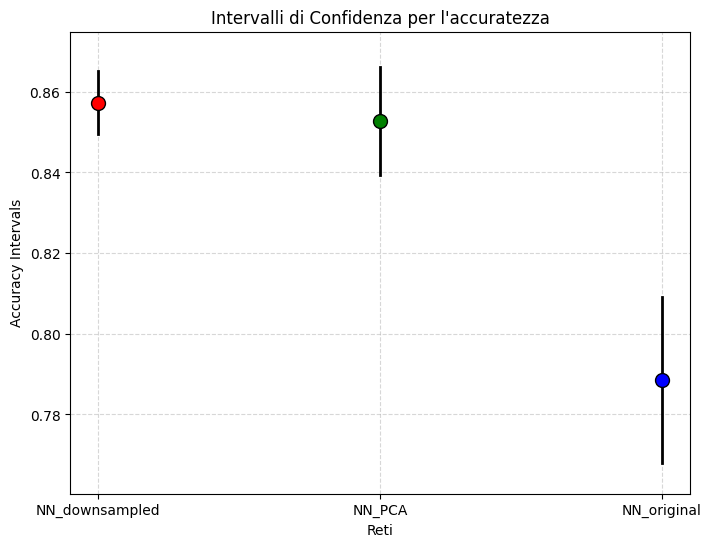

In [ ]:
# compute mean and confidence interval for the accuracy of nn_downsampled
mean_value_nn_downsampled = np.mean(accuracy_repeated_cv)
confidence_interval_nn_downsampled = stats.t.interval(0.95, len(accuracy_repeated_cv)-1, loc=np.mean(accuracy_repeated_cv), scale=stats.sem(accuracy_repeated_cv))

# compute mean and confidence interval for the accuracy of nn_pca
mean_value_pca_data_orig = np.mean(accuracy_repeated_nn_pca_data_orig)
confidence_interval_pca_data_orig = stats.t.interval(0.95, len(accuracy_repeated_nn_pca_data_orig)-1, loc=np.mean(accuracy_repeated_nn_pca_data_orig), scale=stats.sem(accuracy_repeated_nn_pca_data_orig))

# compute mean and confidence interval for the accuracy of nn_original
mean_value_data_orig = np.mean(accuracy_repeated_nn_data_orig)
confidence_interval_data_orig = stats.t.interval(0.95, len(accuracy_repeated_nn_data_orig)-1, loc=np.mean(accuracy_repeated_nn_data_orig), scale=stats.sem(accuracy_repeated_nn_data_orig))

# summary data structures
mean_values = [mean_value_nn_downsampled, mean_value_pca_data_orig, mean_value_data_orig]
ci_lower_values = [confidence_interval_nn_downsampled[0], confidence_interval_pca_data_orig[0], confidence_interval_data_orig[0]]
ci_upper_values = [confidence_interval_nn_downsampled[1], confidence_interval_pca_data_orig[1], confidence_interval_data_orig[1]]

# data for the plot
reti = ["NN_downsampled", "NN_PCA", "NN_original"]
colors = ["red", "green", "blue"]

# limits for the y axis
y_min = min(ci_lower_values) - 0.01 * abs(min(ci_lower_values))
y_max = max(ci_upper_values) + 0.01 * abs(max(ci_upper_values))

# plot creation
plt.figure(figsize=(8, 6))

# draw the bars for the confidence intervals and draw the mean points
for i in range(len(reti)):
    plt.plot([i, i], [ci_lower_values[i], ci_upper_values[i]], color="black", linewidth=2)  # Black bars
    plt.scatter(i, mean_values[i], color=colors[i], s=100, edgecolor="black", zorder=3)  # Colored mean points


plt.xticks(range(len(reti)), reti)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.7)
plt.xlabel("Reti")
plt.ylabel("Accuracy Intervals")
plt.title("Intervalli di Confidenza per l'accuratezza")
plt.ylim(y_min, y_max)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

The NN_downsampled network is the most accurate.

#### F1-score intervals plot

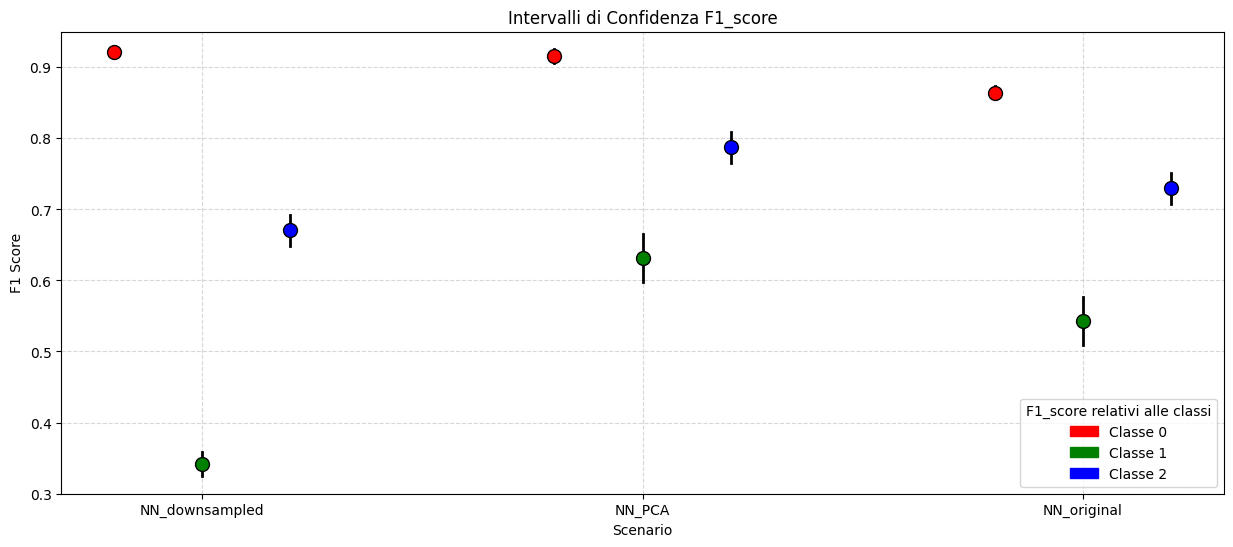

In [ ]:
# compute means and accuracy intervals for the F1-scores of each class.
# nn_downsampled
mean_value_f1_score_nn_downsampled = [[],[],[]]
confidence_interval_f1_nn_downsampled = [[],[],[]]
for i in range(3):
  mean_value_f1_score_nn_downsampled[i] = np.mean(f1_scores_per_class[i])
  confidence_interval_f1_nn_downsampled[i] = stats.t.interval(0.95, len(f1_scores_per_class[i])-1, loc=np.mean(f1_scores_per_class[i]), scale=stats.sem(f1_scores_per_class[i]))

# compute means and accuracy intervals for the F1-scores of each class.
# nn_pca
mean_value_f1_score_pca_data_orig_pca = [[],[],[]]
confidence_interval_f1_pca_data_orig_pca = [[],[],[]]
for i in range(3):
  mean_value_f1_score_pca_data_orig_pca[i] = np.mean(f1_scores_per_class_pca_data_orig[i])
  confidence_interval_f1_pca_data_orig_pca[i] = stats.t.interval(0.95, len(f1_scores_per_class_pca_data_orig[i])-1, loc=np.mean(f1_scores_per_class_pca_data_orig[i]), scale=stats.sem(f1_scores_per_class_pca_data_orig[i]))

# compute means and accuracy intervals for the F1-scores of each class.
# nn_original
mean_value_f1_score_data_orig_pca = [[],[],[]]
confidence_interval_f1_data_orig_pca = [[],[],[]]
for i in range(3):
  mean_value_f1_score_data_orig_pca[i] = np.mean(f1_scores_per_class_data_orig[i])
  confidence_interval_f1_data_orig_pca[i] = stats.t.interval(0.95, len(f1_scores_per_class_data_orig[i])-1, loc=np.mean(f1_scores_per_class_data_orig[i]), scale=stats.sem(f1_scores_per_class_pca_data_orig[i]))

# summary data structure
reti = [
    {
        "name": "NN_downsampled",
        "means": mean_value_f1_score_nn_downsampled,
        "cis": confidence_interval_f1_nn_downsampled
    },
    {
        "name": "NN_PCA",
        "means": mean_value_f1_score_pca_data_orig_pca,
        "cis": confidence_interval_f1_pca_data_orig_pca
    },
    {
        "name": "NN_original",
        "means": mean_value_f1_score_data_orig_pca,
        "cis": confidence_interval_f1_data_orig_pca
    }
]

# set the colors for the 3 classes
colors = ["red", "green", "blue"]

# offsets to position the three confidence intervals of a network
offsets = [-0.2, 0, 0.2]

# plot creation
plt.figure(figsize=(15, 6))
for i, sc in enumerate(reti):
    for j in range(3):
        x_pos = i + offsets[j]
        ci_lower, ci_upper = sc["cis"][j]
        mean_val = sc["means"][j]
        # draw the interval line
        plt.plot([x_pos, x_pos], [ci_lower, ci_upper], color="black", linewidth=2)
        # draw the mean point
        plt.scatter(x_pos, mean_val, color=colors[j], s=100, edgecolor="black", zorder=3)

# legend with colored boxes
legend_elements = [
    mpatches.Patch(color=colors[0], label="Classe 0"),
    mpatches.Patch(color=colors[1], label="Classe 1"),
    mpatches.Patch(color=colors[2], label="Classe 2")
]
plt.legend(handles=legend_elements, title="F1_score relativi alle classi", loc="lower right")


plt.xticks(range(len(reti)), [sc["name"] for sc in reti])
plt.axhline(0, color='grey', linestyle='--', linewidth=0.7)
plt.xlabel("Scenario")
plt.ylabel("F1 Score")
plt.title("Intervalli di Confidenza F1_score")
plt.ylim(0.3, 0.95)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

The NN_PCA network, despite being less accurate than the NN_downsampled network, appears to be the best network, since its confidence intervals for the F1-scores of the three classes are better than those of the other two networks.

# Evaluation of the decision tree (T1)

In [ ]:
rkf = RepeatedKFold(n_splits=7, n_repeats=2, random_state=42)
rkf.get_n_splits(df_originale)

14

In [ ]:
accuracy_repeated_cv_tree = []
f1_scores_per_class_tree = [[],[],[]]
for n_fold, (train_idx, valid_idx) in enumerate(rkf.split(df_originale[variabili_numeriche])):
        # splitting of the dataset
        X_train, X_valid = df_originale[variabili_numeriche].iloc[train_idx], df_originale[variabili_numeriche].iloc[valid_idx]
        y_train, y_valid = df_originale["fetal_health"].iloc[train_idx], df_originale["fetal_health"].iloc[valid_idx]

        # create the tree
        model = DecisionTreeClassifier(random_state=42, ccp_alpha = complex_param1, class_weight="balanced")

        # tree training
        model = model.fit(X_train, y_train)

        # tree test
        y_pred_valid = model.predict(X_valid)

        # compute accuracy
        accuracy_repeated_cv_tree.append(accuracy_score(y_valid,y_pred_valid))

        # compute f1 score
        for class_idx in np.sort(df_originale["fetal_health"].unique()):
          f1 = f1_score(y_valid, y_pred_valid, average='macro', labels=[class_idx])
          f1_scores_per_class_tree[class_idx].append(f1)

In [ ]:
accuracy_repeated_cv_tree

[0.8848684210526315,
 0.8486842105263158,
 0.8717105263157895,
 0.8388157894736842,
 0.8421052631578947,
 0.8910891089108911,
 0.9042904290429042,
 0.8585526315789473,
 0.9046052631578947,
 0.8421052631578947,
 0.9177631578947368,
 0.9046052631578947,
 0.8646864686468647,
 0.8745874587458746]

#### Confidence interval for the accuracy

In [ ]:
st.t.interval(confidence=0.90, df=len(accuracy_repeated_cv_tree)-1, loc=np.mean(accuracy_repeated_cv_tree), scale=st.sem(accuracy_repeated_cv_tree))

(0.86219779281545, 0.8875835293017239)

#### Confidence intervals for the F1-scores

In [ ]:
intervalli_confidenza_f1_score(f1_scores_per_class_tree)

Intervallo di confidenza F1-score per la classe 0: (0.9075062324705979, 0.9308972050819077)
Intervallo di confidenza F1-score per la classe 1: (0.6817252454364415, 0.7247697539945837)
Intervallo di confidenza F1-score per la classe 2: (0.8217519918167778, 0.86271326904635)


# Comparison between decision tree T1 and the NN_PCA network

## Accuracy intervals plot

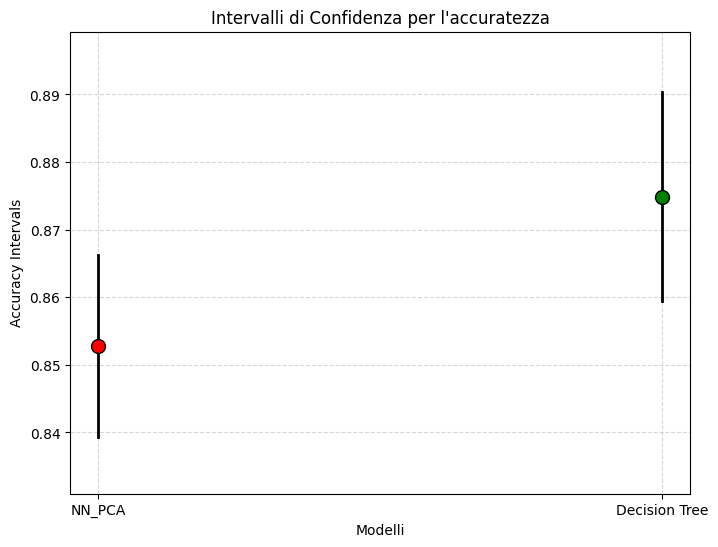

In [ ]:
# compute mean and confidence interval for the accuracy of nn_pca
mean_value_pca_data_orig = np.mean(accuracy_repeated_nn_pca_data_orig)
confidence_interval_pca_data_orig = stats.t.interval(0.95, len(accuracy_repeated_nn_pca_data_orig)-1, loc=np.mean(accuracy_repeated_nn_pca_data_orig), scale=stats.sem(accuracy_repeated_nn_pca_data_orig))

# compute mean and confidence interval for the accuracy of decision tree T1
mean_value_tree = np.mean(accuracy_repeated_cv_tree)
confidence_interval_tree = stats.t.interval(0.95, len(accuracy_repeated_cv_tree)-1, loc=np.mean(accuracy_repeated_cv_tree), scale=stats.sem(accuracy_repeated_cv_tree))

# data for the plot
reti = ["NN_PCA", "Decision Tree"]
colors = ["red", "green", "blue"]

# summary data structures
mean_values = [mean_value_pca_data_orig, mean_value_tree]
ci_lower_values = [confidence_interval_pca_data_orig[0], confidence_interval_tree[0]]
ci_upper_values = [confidence_interval_pca_data_orig[1], confidence_interval_tree[1]]

# limits for the y axis
y_min = min(ci_lower_values) - 0.01 * abs(min(ci_lower_values))
y_max = max(ci_upper_values) + 0.01 * abs(max(ci_upper_values))

# plot creation
plt.figure(figsize=(8, 6))

# draw the bars for the confidence intervals and draw the mean points
for i in range(len(reti)):
    plt.plot([i, i], [ci_lower_values[i], ci_upper_values[i]], color="black", linewidth=2)  # Black bars
    plt.scatter(i, mean_values[i], color=colors[i], s=100, edgecolor="black", zorder=3)  # Colored mean points

plt.xticks(range(len(reti)), reti)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.7)
plt.xlabel("Modelli")
plt.ylabel("Accuracy Intervals")
plt.title("Intervalli di Confidenza per l'accuratezza")
plt.ylim(y_min, y_max)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## F1-score intervals plot

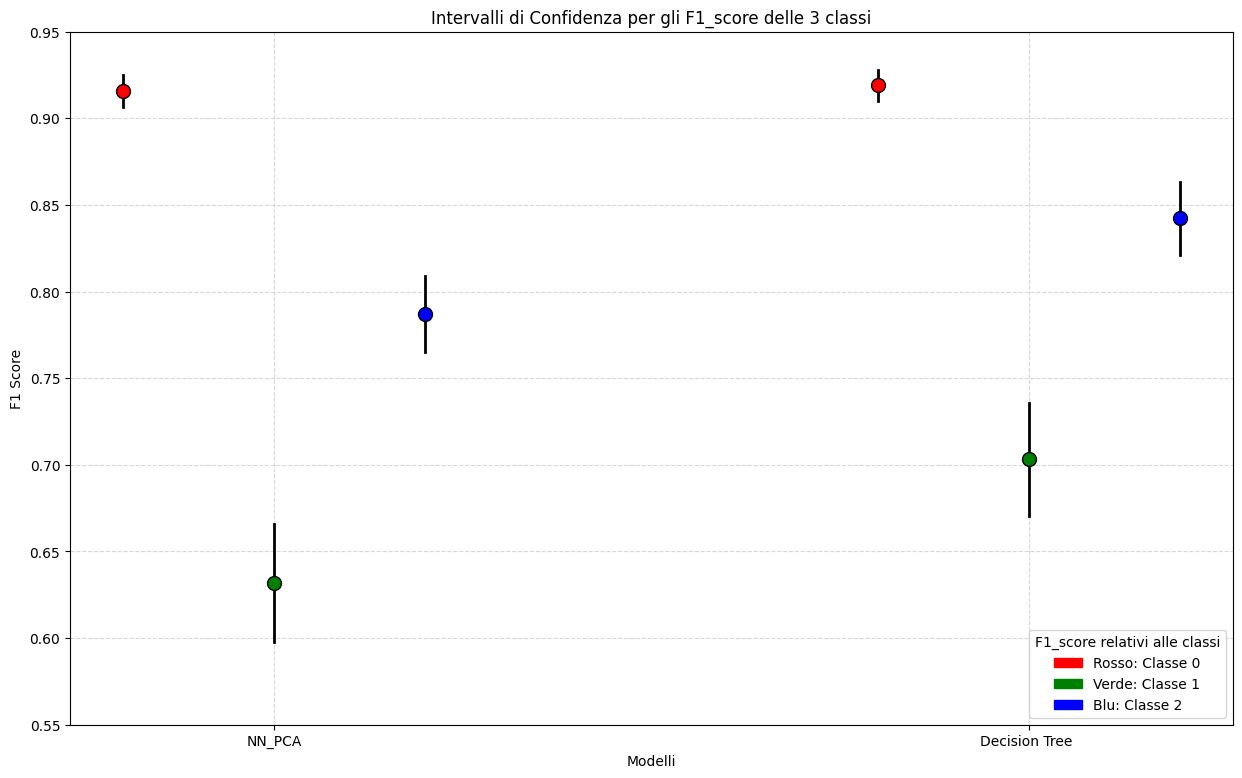

In [ ]:
# compute means and confidence intervals of the F1-scores for each class.
# nn_pca network
mean_value_f1_score_pca_data_orig_pca = [[],[],[]]
confidence_interval_f1_pca_data_orig_pca = [[],[],[]]
for i in range(3):
  mean_value_f1_score_pca_data_orig_pca[i] = np.mean(f1_scores_per_class_pca_data_orig[i])
  confidence_interval_f1_pca_data_orig_pca[i] = stats.t.interval(0.95, len(f1_scores_per_class_pca_data_orig[i])-1, loc=np.mean(f1_scores_per_class_pca_data_orig[i]), scale=stats.sem(f1_scores_per_class_pca_data_orig[i]))

# compute means and confidence intervals of the F1-scores for each class.
# decision tree T1
mean_value_f1_score_tree = [[],[],[]]
confidence_interval_f1_tree = [[],[],[]]
for i in range(3):
  mean_value_f1_score_tree[i] = np.mean(f1_scores_per_class_tree[i])
  confidence_interval_f1_tree[i] = stats.t.interval(0.95, len(f1_scores_per_class_tree[i])-1, loc=np.mean(f1_scores_per_class_tree[i]), scale=stats.sem(f1_scores_per_class_pca_data_orig[i]))

# summary data structure
reti = [
    {
        "name": "NN_PCA",
        "means": mean_value_f1_score_pca_data_orig_pca,
        "cis": confidence_interval_f1_pca_data_orig_pca
    },
    {
        "name": "Decision Tree ",
        "means": mean_value_f1_score_tree,
        "cis": confidence_interval_f1_tree
    }
]

# colors for the 3 classes
colors = ["red", "green", "blue"]

# Offsets to position the confidence interval bars of a model
offsets = [-0.2, 0, 0.2]

# plot creation
plt.figure(figsize=(15, 9))
for i, sc in enumerate(reti):
    for j in range(3):
        x_pos = i + offsets[j]
        ci_lower, ci_upper = sc["cis"][j]
        mean_val = sc["means"][j]
        # draw the interval line
        plt.plot([x_pos, x_pos], [ci_lower, ci_upper], color="black", linewidth=2)
        # draw the mean point
        plt.scatter(x_pos, mean_val, color=colors[j], s=100, edgecolor="black", zorder=3)

# legend with colored boxes
legend_elements = [
    mpatches.Patch(color=colors[0], label="Rosso: Classe 0"),
    mpatches.Patch(color=colors[1], label="Verde: Classe 1"),
    mpatches.Patch(color=colors[2], label="Blu: Classe 2")
]
plt.legend(handles=legend_elements, title="F1_score relativi alle classi", loc="lower right")

plt.xticks(range(len(reti)), [sc["name"] for sc in reti])
plt.axhline(0, color='grey', linestyle='--', linewidth=0.7)
plt.xlabel("Modelli")
plt.ylabel("F1 Score")
plt.title("Intervalli di Confidenza per gli F1_score delle 3 classi")
plt.ylim(0.55, 0.95)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()